<a href="https://colab.research.google.com/github/aditik-20/CivicShield/blob/main/CivicShield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# URBANRISK AI
# PHASE 1 — DATA COLLECTION
# STEP 1 — IMPORT LIBRARIES
# ============================================

import os
import numpy as np
import pandas as pd
import dask.dataframe as dd
import matplotlib.pyplot as plt
import seaborn as sns

from pyproj import Transformer

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================
# STEP 2 — DOWNLOAD ACCIDENT DATASET
# ============================================

import kagglehub

accident_path = kagglehub.dataset_download(
    "ishmaelkiptoo/motor-vehicle-collisions"
)

print("Accident dataset downloaded.")
print("Path:", accident_path)

100%|██████████| 79.7M/79.7M [00:00<00:00, 143MB/s]

Extracting files...


Accident dataset downloaded.
Path: /root/.cache/kagglehub/datasets/ishmaelkiptoo/motor-vehicle-collisions/versions/1


In [3]:
# ============================================
# STEP 3 — DOWNLOAD TRAFFIC DATASET
# ============================================

traffic_path = kagglehub.dataset_download(
    "aadimator/nyc-automated-traffic-volume-counts"
)

print("Traffic dataset downloaded.")
print("Path:", traffic_path)

100%|██████████| 1.19G/1.19G [00:14<00:00, 88.5MB/s]

Extracting files...


Traffic dataset downloaded.
Path: /root/.cache/kagglehub/datasets/aadimator/nyc-automated-traffic-volume-counts/versions/1


In [4]:
# ============================================
# STEP 4 — CHECK DATASET FILES
# ============================================

print("========== ACCIDENT DATASET FILES ==========")

for root, dirs, files in os.walk(accident_path):
    for file in files:
        print(os.path.join(root, file))


print("\n========== TRAFFIC DATASET FILES ==========")

for root, dirs, files in os.walk(traffic_path):
    for file in files:
        print(os.path.join(root, file))

========== ACCIDENT DATASET FILES ==========
/root/.cache/kagglehub/datasets/ishmaelkiptoo/motor-vehicle-collisions/versions/1/Motor_Vehicle_Collisions.csv

========== TRAFFIC DATASET FILES ==========
/root/.cache/kagglehub/datasets/aadimator/nyc-automated-traffic-volume-counts/versions/1/Automated_Traffic_Volume_Counts.csv


In [5]:
# ============================================
# STEP 5 — SET DATASET FILE PATHS
# ============================================

accident_file = os.path.join(
    accident_path,
    "Motor_Vehicle_Collisions.csv"
)

traffic_file = os.path.join(
    traffic_path,
    "Automated_Traffic_Volume_Counts.csv"
)

print("Accident file:")
print(accident_file)

print("\nTraffic file:")
print(traffic_file)

Accident file:
/root/.cache/kagglehub/datasets/ishmaelkiptoo/motor-vehicle-collisions/versions/1/Motor_Vehicle_Collisions.csv

Traffic file:
/root/.cache/kagglehub/datasets/aadimator/nyc-automated-traffic-volume-counts/versions/1/Automated_Traffic_Volume_Counts.csv


In [6]:
# ============================================
# STEP 6 — LOAD ACCIDENT DATASET
# ============================================

accident_df = pd.read_csv(
    accident_file,
    low_memory=False
)

print("========== ACCIDENT DATASET ==========")

print("Rows:", len(accident_df))
print("Columns:", len(accident_df.columns))

print("\nShape:")
print(accident_df.shape)

print("\nColumns:")
print(accident_df.columns.tolist())

========== ACCIDENT DATASET ==========
Rows: 2034019
Columns: 29

Shape:
(2034019, 29)

Columns:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']


In [7]:
# ============================================
# STEP 7 — LOAD TRAFFIC DATASET
# ============================================

traffic_df = dd.read_csv(
    traffic_file,
    assume_missing=True
)

print("========== TRAFFIC DATASET ==========")

print("Number of columns:",
      len(traffic_df.columns))

print("\nTraffic columns:")
print(traffic_df.columns.tolist())

========== TRAFFIC DATASET ==========
Number of columns: 14

Traffic columns:
['RequestID', 'Boro', 'Yr', 'M', 'D', 'HH', 'MM', 'Vol', 'SegmentID', 'WktGeom', 'street', 'fromSt', 'toSt', 'Direction']


In [8]:
# ============================================
# STEP 8 — BASIC DATA PREVIEW
# ============================================

print("========== ACCIDENT SAMPLE ==========")

display(
    accident_df.head(5)
)

print("\n========== TRAFFIC SAMPLE ==========")

display(
    traffic_df.head(5)
)

========== ACCIDENT SAMPLE ==========


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,09/11/2021,2:39,NaN,NaN,NaN,NaN,NaN,WHITESTONE EXPRESSWAY,20 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,4455765,Sedan,Sedan,NaN,NaN,NaN
1,03/26/2022,11:45,NaN,NaN,NaN,NaN,NaN,QUEENSBORO BRIDGE UPPER,NaN,NaN,...,NaN,NaN,NaN,NaN,4513547,Sedan,NaN,NaN,NaN,NaN
2,06/29/2022,6:55,NaN,NaN,NaN,NaN,NaN,THROGS NECK BRIDGE,NaN,NaN,...,Unspecified,NaN,NaN,NaN,4541903,Sedan,Pick-up Truck,NaN,NaN,NaN
3,09/11/2021,9:35,BROOKLYN,11208,40.667202,-73.866500,"(40.667202, -73.8665)",NaN,NaN,1211 LORING AVENUE,...,NaN,NaN,NaN,NaN,4456314,Sedan,NaN,NaN,NaN,NaN
4,12/14/2021,8:13,BROOKLYN,11233,40.683304,-73.917274,"(40.683304, -73.917274)",SARATOGA AVENUE,DECATUR STREET,NaN,...,NaN,NaN,NaN,NaN,4486609,NaN,NaN,NaN,NaN,NaN



========== TRAFFIC SAMPLE ==========


,RequestID,Boro,Yr,M,D,HH,MM,Vol,SegmentID,WktGeom,street,fromSt,toSt,Direction
0,20856.0,Queens,2015.0,6.0,23.0,23.0,30.0,9.0,171896.0,POINT (1052296.600156678 199785.26932711253),94 AVENUE,207 Street,Francis Lewis Boulevard,WB
1,21231.0,Staten Island,2015.0,9.0,14.0,4.0,15.0,6.0,9896.0,POINT (942668.0589509147 171441.21296926),RICHMOND TERRACE,Wright Avenue,Emeric Court,WB
2,29279.0,Bronx,2017.0,10.0,19.0,4.0,30.0,85.0,77817.0,POINT (1016508.0034050211 235221.59092266942),HUNTS POINT AVENUE,Whittier Street,Randall Avenue,NB
3,27019.0,Brooklyn,2017.0,11.0,7.0,18.0,30.0,168.0,188023.0,POINT (992925.4316054962 184116.82855457635),FLATBUSH AVENUE,Brighton Line,Brighton Line,NB
4,26734.0,Manhattan,2017.0,11.0,3.0,22.0,0.0,355.0,137516.0,POINT (1004175.9505178436 247779.63624949602),WASHINGTON BRIDGE,Harlem River Shoreline,Harlem River Shoreline,EB


In [9]:
# ============================================
# PHASE 2 — DATA UNDERSTANDING
# STEP 9 — ACCIDENT DATA OVERVIEW
# ============================================

print("========== ACCIDENT DATA OVERVIEW ==========")

print("Shape:", accident_df.shape)

print("\nData types:")
display(accident_df.dtypes)

print("\nFirst 5 records:")
display(accident_df.head())

========== ACCIDENT DATA OVERVIEW ==========
Shape: (2034019, 29)

Data types:


,0
CRASH DATE,object
CRASH TIME,object
BOROUGH,object
ZIP CODE,object
LATITUDE,float64
LONGITUDE,float64
LOCATION,object
ON STREET NAME,object
CROSS STREET NAME,object
OFF STREET NAME,object



First 5 records:


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,09/11/2021,2:39,NaN,NaN,NaN,NaN,NaN,WHITESTONE EXPRESSWAY,20 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,4455765,Sedan,Sedan,NaN,NaN,NaN
1,03/26/2022,11:45,NaN,NaN,NaN,NaN,NaN,QUEENSBORO BRIDGE UPPER,NaN,NaN,...,NaN,NaN,NaN,NaN,4513547,Sedan,NaN,NaN,NaN,NaN
2,06/29/2022,6:55,NaN,NaN,NaN,NaN,NaN,THROGS NECK BRIDGE,NaN,NaN,...,Unspecified,NaN,NaN,NaN,4541903,Sedan,Pick-up Truck,NaN,NaN,NaN
3,09/11/2021,9:35,BROOKLYN,11208,40.667202,-73.866500,"(40.667202, -73.8665)",NaN,NaN,1211 LORING AVENUE,...,NaN,NaN,NaN,NaN,4456314,Sedan,NaN,NaN,NaN,NaN
4,12/14/2021,8:13,BROOKLYN,11233,40.683304,-73.917274,"(40.683304, -73.917274)",SARATOGA AVENUE,DECATUR STREET,NaN,...,NaN,NaN,NaN,NaN,4486609,NaN,NaN,NaN,NaN,NaN


In [10]:
# ============================================
# STEP 10 — ACCIDENT MISSING VALUES
# ============================================

print("========== ACCIDENT MISSING VALUES ==========")

accident_missing = (
    accident_df.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    accident_missing.to_frame("Missing Values")
)

========== ACCIDENT MISSING VALUES ==========


,Missing Values
VEHICLE TYPE CODE 5,2025502
CONTRIBUTING FACTOR VEHICLE 5,2025235
VEHICLE TYPE CODE 4,2002641
CONTRIBUTING FACTOR VEHICLE 4,2001552
VEHICLE TYPE CODE 3,1894593
CONTRIBUTING FACTOR VEHICLE 3,1889497
OFF STREET NAME,1697226
CROSS STREET NAME,763510
ZIP CODE,633028
BOROUGH,632787


In [11]:
# ============================================
# STEP 11 — TRAFFIC DATA OVERVIEW
# ============================================

print("========== TRAFFIC DATA OVERVIEW ==========")

print("Columns:", len(traffic_df.columns))

print("\nData types:")
display(traffic_df.dtypes)

print("\nFirst 10 records:")
display(
    traffic_df.head(10)
)

========== TRAFFIC DATA OVERVIEW ==========
Columns: 14

Data types:


,0
RequestID,float64
Boro,string[pyarrow]
Yr,float64
M,float64
D,float64
HH,float64
MM,float64
Vol,float64
SegmentID,float64
WktGeom,string[pyarrow]



First 10 records:


,RequestID,Boro,Yr,M,D,HH,MM,Vol,SegmentID,WktGeom,street,fromSt,toSt,Direction
0,20856.0,Queens,2015.0,6.0,23.0,23.0,30.0,9.0,171896.0,POINT (1052296.600156678 199785.26932711253),94 AVENUE,207 Street,Francis Lewis Boulevard,WB
1,21231.0,Staten Island,2015.0,9.0,14.0,4.0,15.0,6.0,9896.0,POINT (942668.0589509147 171441.21296926),RICHMOND TERRACE,Wright Avenue,Emeric Court,WB
2,29279.0,Bronx,2017.0,10.0,19.0,4.0,30.0,85.0,77817.0,POINT (1016508.0034050211 235221.59092266942),HUNTS POINT AVENUE,Whittier Street,Randall Avenue,NB
3,27019.0,Brooklyn,2017.0,11.0,7.0,18.0,30.0,168.0,188023.0,POINT (992925.4316054962 184116.82855457635),FLATBUSH AVENUE,Brighton Line,Brighton Line,NB
4,26734.0,Manhattan,2017.0,11.0,3.0,22.0,0.0,355.0,137516.0,POINT (1004175.9505178436 247779.63624949602),WASHINGTON BRIDGE,Harlem River Shoreline,Harlem River Shoreline,EB
5,26015.0,Bronx,2017.0,6.0,17.0,1.0,45.0,11.0,86053.0,POINT (1021709.470909429 248612.86356908735),WALLACE AVENUE,Rhinelander Avenue,Bronxdale Avenue,NB
6,2033.0,Manhattan,2009.0,9.0,1.0,18.0,30.0,99.0,70683.0,POINT (1000954.8 243914.9),S/B AMSTERDAM AVE @ W 162 ST,ST NICHOLAS AV/W 162 ST,W 163 ST,SB
7,23133.0,Queens,2016.0,3.0,21.0,9.0,45.0,232.0,101101.0,POINT (1050277.3347521287 216784.58047417598),NORTHERN BOULEVARD,220 Place,220 Street,WB
8,32417.0,Queens,2020.0,11.0,14.0,2.0,15.0,18.0,147877.0,POINT (1044172.6626552071 200130.04842303603),MIDLAND PARKWAY,Dalny Road,Connector,SB
9,26198.0,Bronx,2017.0,6.0,22.0,4.0,30.0,2.0,85935.0,POINT (1021747.2311522859 242463.04655740186),THIERIOT AVENUE,Gleason Avenue,Pelham Line,NB


In [12]:
# ============================================
# STEP 12 — TRAFFIC BASIC STATISTICS
# ============================================

print("========== TRAFFIC BASIC STATISTICS ==========")

print("Traffic rows:",
      traffic_df.shape[0].compute())

print("\nTraffic volume statistics:")

traffic_volume_stats = (
    traffic_df["Vol"]
    .describe()
    .compute()
)

display(
    traffic_volume_stats
)

print("\nUnique SegmentIDs:")

unique_segments = (
    traffic_df["SegmentID"]
    .nunique()
    .compute()
)

print(unique_segments)

========== TRAFFIC BASIC STATISTICS ==========
Traffic rows: 27190511

Traffic volume statistics:


,Vol
count,2.719051e+07
mean,1.068197e+02
std,1.567890e+02
min,-1.000000e+00
25%,2.100000e+01
50%,6.100000e+01
75%,1.330000e+02
max,3.276700e+04



Unique SegmentIDs:
14953


In [13]:
# ============================================
# PHASE 2 — DATA UNDERSTANDING
# STEP 13 — ACCIDENT DATE/TIME COVERAGE
# ============================================

print("========== ACCIDENT DATE/TIME ==========")

accident_df["CRASH_DATE_DT"] = pd.to_datetime(
    accident_df["CRASH DATE"],
    errors="coerce"
)

accident_time_dt = pd.to_datetime(
    accident_df["CRASH TIME"],
    format="%H:%M",
    errors="coerce"
)

accident_df["ACCIDENT_HOUR"] = accident_time_dt.dt.hour

print("Earliest accident date:",
      accident_df["CRASH_DATE_DT"].min())

print("Latest accident date:",
      accident_df["CRASH_DATE_DT"].max())

print("Invalid dates:",
      accident_df["CRASH_DATE_DT"].isna().sum())

print("Invalid times:",
      accident_df["ACCIDENT_HOUR"].isna().sum())

print("\nAccidents by year:")

accident_years = (
    accident_df["CRASH_DATE_DT"]
    .dt.year
    .value_counts()
    .sort_index()
)

display(
    accident_years.to_frame("Accident Count")
)

========== ACCIDENT DATE/TIME ==========
Earliest accident date: 2012-07-01 00:00:00
Latest accident date: 2023-10-13 00:00:00
Invalid dates: 0
Invalid times: 0

Accidents by year:


,Accident Count
CRASH_DATE_DT,
2012,100545
2013,203740
2014,206033
2015,217694
2016,229831
2017,231007
2018,231564
2019,211486
2020,112916


In [14]:
# ============================================
# STEP 14 — ACCIDENT COORDINATES
# ============================================

print("========== ACCIDENT COORDINATES ==========")

print("Missing latitude:",
      accident_df["LATITUDE"].isna().sum())

print("Missing longitude:",
      accident_df["LONGITUDE"].isna().sum())

print("\nLatitude range:")
print(
    accident_df["LATITUDE"].min(),
    "to",
    accident_df["LATITUDE"].max()
)

print("\nLongitude range:")
print(
    accident_df["LONGITUDE"].min(),
    "to",
    accident_df["LONGITUDE"].max()
)

# Valid NYC coordinate check
valid_coordinates = (
    accident_df["LATITUDE"].between(40, 42) &
    accident_df["LONGITUDE"].between(-75, -72)
)

print(
    "\nValid NYC coordinates:",
    valid_coordinates.sum()
)

print(
    "Invalid/missing coordinates:",
    (~valid_coordinates).sum()
)

========== ACCIDENT COORDINATES ==========
Missing latitude: 230884
Missing longitude: 230884

Latitude range:
0.0 to 43.344444

Longitude range:
-201.35999 to 0.0

Valid NYC coordinates: 1798731
Invalid/missing coordinates: 235288


In [15]:
# ============================================
# STEP 15 — TRAFFIC DATE/TIME COVERAGE
# ============================================

print("========== TRAFFIC DATE/TIME ==========")

traffic_min_year = (
    traffic_df["Yr"].min().compute()
)

traffic_max_year = (
    traffic_df["Yr"].max().compute()
)

traffic_min_month = (
    traffic_df["M"].min().compute()
)

traffic_max_month = (
    traffic_df["M"].max().compute()
)

print(
    "Traffic year range:",
    traffic_min_year,
    "to",
    traffic_max_year
)

print(
    "Traffic month range:",
    traffic_min_month,
    "to",
    traffic_max_month
)

print(
    "\nTraffic hour range:"
)

print(
    traffic_df["HH"].min().compute(),
    "to",
    traffic_df["HH"].max().compute()
)

========== TRAFFIC DATE/TIME ==========
Traffic year range: 2000.0 to 2020.0
Traffic month range: 1.0 to 12.0

Traffic hour range:
0.0 to 23.0


In [16]:
# ============================================
# STEP 16 — TRAFFIC SEGMENT VALIDATION
# ============================================

print("========== TRAFFIC SEGMENT VALIDATION ==========")

unique_segments = (
    traffic_df["SegmentID"]
    .nunique()
    .compute()
)

missing_segments = (
    traffic_df["SegmentID"]
    .isna()
    .sum()
    .compute()
)

missing_volume = (
    traffic_df["Vol"]
    .isna()
    .sum()
    .compute()
)

negative_volume = (
    (traffic_df["Vol"] < 0)
    .sum()
    .compute()
)

print("Unique SegmentIDs:", unique_segments)

print("Missing SegmentIDs:", missing_segments)

print("Missing traffic volume:", missing_volume)

print("Negative traffic volume:", negative_volume)

========== TRAFFIC SEGMENT VALIDATION ==========
Unique SegmentIDs: 14953
Missing SegmentIDs: 0
Missing traffic volume: 0
Negative traffic volume: 7


In [17]:
# ============================================
# PHASE 3 — DATA CLEANING
# STEP 17 — CLEAN DATE & TIME
# ============================================

print("========== CLEANING ACCIDENT DATE/TIME ==========")

# Remove records with invalid date/time
before = len(accident_df)

accident_df = accident_df.dropna(
    subset=[
        "CRASH_DATE_DT",
        "ACCIDENT_HOUR"
    ]
).copy()

after = len(accident_df)

print("Records before:", before)
print("Records after:", after)
print("Records removed:", before - after)

print("\nInvalid dates remaining:",
      accident_df["CRASH_DATE_DT"].isna().sum())

print("Invalid hours remaining:",
      accident_df["ACCIDENT_HOUR"].isna().sum())

========== CLEANING ACCIDENT DATE/TIME ==========
Records before: 2034019
Records after: 2034019
Records removed: 0

Invalid dates remaining: 0
Invalid hours remaining: 0


In [18]:
# ============================================
# STEP 18 — CLEAN ACCIDENT COORDINATES
# ============================================

print("========== CLEANING COORDINATES ==========")

before = len(accident_df)

valid_coordinates = (
    accident_df["LATITUDE"].between(40, 42) &
    accident_df["LONGITUDE"].between(-75, -72)
)

accident_df = accident_df[
    valid_coordinates
].copy()

after = len(accident_df)

print("Records before:", before)
print("Records after:", after)
print("Records removed:", before - after)

print("\nLatitude range:")
print(
    accident_df["LATITUDE"].min(),
    "to",
    accident_df["LATITUDE"].max()
)

print("\nLongitude range:")
print(
    accident_df["LONGITUDE"].min(),
    "to",
    accident_df["LONGITUDE"].max()
)

========== CLEANING COORDINATES ==========
Records before: 2034019
Records after: 1798731
Records removed: 235288

Latitude range:
40.4989488 to 41.34796

Longitude range:
-74.742 to -73.66301


In [19]:
# ============================================
# STEP 18 — CLEAN ACCIDENT COORDINATES
# ============================================

print("========== CLEANING COORDINATES ==========")

before = len(accident_df)

valid_coordinates = (
    accident_df["LATITUDE"].between(40, 42) &
    accident_df["LONGITUDE"].between(-75, -72)
)

accident_df = accident_df[
    valid_coordinates
].copy()

after = len(accident_df)

print("Records before:", before)
print("Records after:", after)
print("Records removed:", before - after)

print("\nLatitude range:")
print(
    accident_df["LATITUDE"].min(),
    "to",
    accident_df["LATITUDE"].max()
)

print("\nLongitude range:")
print(
    accident_df["LONGITUDE"].min(),
    "to",
    accident_df["LONGITUDE"].max()
)

========== CLEANING COORDINATES ==========
Records before: 1798731
Records after: 1798731
Records removed: 0

Latitude range:
40.4989488 to 41.34796

Longitude range:
-74.742 to -73.66301


In [20]:
# ============================================
# STEP 19 — DUPLICATE ACCIDENT CHECK
# ============================================

print("========== DUPLICATE ACCIDENT CHECK ==========")

duplicate_ids = (
    accident_df["COLLISION_ID"]
    .duplicated()
    .sum()
)

print("Duplicate COLLISION_ID records:",
      duplicate_ids)

print(
    "Unique COLLISION_ID:",
    accident_df["COLLISION_ID"].nunique()
)

print(
    "Total accident records:",
    len(accident_df)
)

========== DUPLICATE ACCIDENT CHECK ==========
Duplicate COLLISION_ID records: 0
Unique COLLISION_ID: 1798731
Total accident records: 1798731


In [21]:
# ============================================
# STEP 20 — CLEAN TRAFFIC VOLUME
# ============================================

print("========== CLEANING TRAFFIC VOLUME ==========")

negative_before = (
    (traffic_df["Vol"] < 0)
    .sum()
    .compute()
)

print(
    "Negative traffic values before:",
    negative_before
)

# Convert invalid negative volume to NaN
traffic_df["Vol"] = traffic_df["Vol"].mask(
    traffic_df["Vol"] < 0,
    np.nan
)

negative_after = (
    (traffic_df["Vol"] < 0)
    .sum()
    .compute()
)

print(
    "Negative traffic values after:",
    negative_after
)

print(
    "Missing traffic volume after cleaning:",
    traffic_df["Vol"]
    .isna()
    .sum()
    .compute()
)

========== CLEANING TRAFFIC VOLUME ==========
Negative traffic values before: 7
Negative traffic values after: 0
Missing traffic volume after cleaning: 7


In [22]:
# ============================================
# PHASE 3 — DATA CLEANING
# STEP 21 — TRAFFIC DATE/TIME
# ============================================

print("========== TRAFFIC DATE/TIME CLEANING ==========")

traffic_df["TRAFFIC_DATETIME"] = dd.to_datetime(
    traffic_df["Yr"].astype(int).astype(str)
    + "-"
    + traffic_df["M"].astype(int).astype(str).str.zfill(2)
    + "-"
    + traffic_df["D"].astype(int).astype(str).str.zfill(2)
    + " "
    + traffic_df["HH"].astype(int).astype(str).str.zfill(2)
    + ":"
    + traffic_df["MM"].astype(int).astype(str).str.zfill(2),
    errors="coerce"
)

invalid_traffic_datetime = (
    traffic_df["TRAFFIC_DATETIME"]
    .isna()
    .sum()
    .compute()
)

print(
    "Invalid traffic timestamps:",
    invalid_traffic_datetime
)

print("\nSample traffic timestamps:")

display(
    traffic_df[
        [
            "Yr",
            "M",
            "D",
            "HH",
            "MM",
            "TRAFFIC_DATETIME"
        ]
    ].head(10)
)

========== TRAFFIC DATE/TIME CLEANING ==========
Invalid traffic timestamps: 0

Sample traffic timestamps:


,Yr,M,D,HH,MM,TRAFFIC_DATETIME
0,2015.0,6.0,23.0,23.0,30.0,2015-06-23 23:30:00
1,2015.0,9.0,14.0,4.0,15.0,2015-09-14 04:15:00
2,2017.0,10.0,19.0,4.0,30.0,2017-10-19 04:30:00
3,2017.0,11.0,7.0,18.0,30.0,2017-11-07 18:30:00
4,2017.0,11.0,3.0,22.0,0.0,2017-11-03 22:00:00
5,2017.0,6.0,17.0,1.0,45.0,2017-06-17 01:45:00
6,2009.0,9.0,1.0,18.0,30.0,2009-09-01 18:30:00
7,2016.0,3.0,21.0,9.0,45.0,2016-03-21 09:45:00
8,2020.0,11.0,14.0,2.0,15.0,2020-11-14 02:15:00
9,2017.0,6.0,22.0,4.0,30.0,2017-06-22 04:30:00


In [23]:
# ============================================
# STEP 22 — TRAFFIC SEGMENT VALIDATION
# ============================================

print("========== TRAFFIC SEGMENT VALIDATION ==========")

missing_segment_ids = (
    traffic_df["SegmentID"]
    .isna()
    .sum()
    .compute()
)

print(
    "Missing SegmentIDs:",
    missing_segment_ids
)

print(
    "Unique SegmentIDs:",
    traffic_df["SegmentID"]
    .nunique()
    .compute()
)

========== TRAFFIC SEGMENT VALIDATION ==========
Missing SegmentIDs: 0
Unique SegmentIDs: 14953


In [24]:
# ============================================
# STEP 23 — INSPECT TRAFFIC GEOMETRY
# ============================================

print("========== TRAFFIC GEOMETRY ==========")

traffic_geometry_sample = (
    traffic_df[
        ["SegmentID", "WktGeom"]
    ]
    .dropna()
    .head(10)
)

display(traffic_geometry_sample)

print("\nWktGeom examples:")

for value in traffic_geometry_sample["WktGeom"]:
    print(value)

========== TRAFFIC GEOMETRY ==========


,SegmentID,WktGeom
0,171896.0,POINT (1052296.600156678 199785.26932711253)
1,9896.0,POINT (942668.0589509147 171441.21296926)
2,77817.0,POINT (1016508.0034050211 235221.59092266942)
3,188023.0,POINT (992925.4316054962 184116.82855457635)
4,137516.0,POINT (1004175.9505178436 247779.63624949602)
5,86053.0,POINT (1021709.470909429 248612.86356908735)
6,70683.0,POINT (1000954.8 243914.9)
7,101101.0,POINT (1050277.3347521287 216784.58047417598)
8,147877.0,POINT (1044172.6626552071 200130.04842303603)
9,85935.0,POINT (1021747.2311522859 242463.04655740186)



WktGeom examples:
POINT (1052296.600156678 199785.26932711253)
POINT (942668.0589509147 171441.21296926)
POINT (1016508.0034050211 235221.59092266942)
POINT (992925.4316054962 184116.82855457635)
POINT (1004175.9505178436 247779.63624949602)
POINT (1021709.470909429 248612.86356908735)
POINT (1000954.8 243914.9)
POINT (1050277.3347521287 216784.58047417598)
POINT (1044172.6626552071 200130.04842303603)
POINT (1021747.2311522859 242463.04655740186)


In [25]:
# ============================================
# STEP 24 — FINAL TRAFFIC VOLUME CHECK
# ============================================

print("========== TRAFFIC VOLUME CHECK ==========")

missing_volume = (
    traffic_df["Vol"]
    .isna()
    .sum()
    .compute()
)

negative_volume = (
    (traffic_df["Vol"] < 0)
    .sum()
    .compute()
)

print("Missing traffic volume:", missing_volume)
print("Negative traffic volume:", negative_volume)

========== TRAFFIC VOLUME CHECK ==========
Missing traffic volume: 7
Negative traffic volume: 0


In [26]:
# ============================================
# PHASE 4 — DATA INTEGRATION
# STEP 25 — COMMON TIME PERIOD
# ============================================

print("========== PHASE 4 — TIME OVERLAP ==========")

# Create accident year
accident_df["ACCIDENT_YEAR"] = (
    accident_df["CRASH_DATE_DT"].dt.year
)

# Traffic coverage
traffic_min_year = int(
    traffic_df["Yr"].min().compute()
)

traffic_max_year = int(
    traffic_df["Yr"].max().compute()
)

print(
    "Traffic coverage:",
    traffic_min_year,
    "to",
    traffic_max_year
)

# Keep only accident years for which traffic data exists
accident_overlap = accident_df[
    accident_df["ACCIDENT_YEAR"].between(
        traffic_min_year,
        traffic_max_year
    )
].copy()

print(
    "\nTotal cleaned accidents:",
    len(accident_df)
)

print(
    "Accidents within traffic coverage:",
    len(accident_overlap)
)

print(
    "Accidents outside traffic coverage:",
    len(accident_df) - len(accident_overlap)
)

print("\nOverlap year range:")
print(
    accident_overlap["ACCIDENT_YEAR"].min(),
    "to",
    accident_overlap["ACCIDENT_YEAR"].max()
)

========== PHASE 4 — TIME OVERLAP ==========
Traffic coverage: 2000 to 2020

Total cleaned accidents: 1798731
Accidents within traffic coverage: 1535963
Accidents outside traffic coverage: 262768

Overlap year range:
2012 to 2020


In [27]:
# ============================================
# STEP 26 — UNIQUE TRAFFIC SEGMENTS
# ============================================

print("========== TRAFFIC SEGMENT LOCATIONS ==========")

traffic_locations = traffic_df[
    ["SegmentID", "WktGeom"]
].dropna()

traffic_locations = (
    traffic_locations
    .drop_duplicates(subset=["SegmentID"])
    .compute()
)

print("Unique traffic segments:", len(traffic_locations))

display(traffic_locations.head(10))

========== TRAFFIC SEGMENT LOCATIONS ==========
Unique traffic segments: 14953


,SegmentID,WktGeom
9,85935.0,POINT (1021747.2311522859 242463.04655740186)
47,36248.0,POINT (993285.443587875 214869.37928834607)
98,78468.0,POINT (1012880 241535.7)
231,48792.0,POINT (1011833.140220576 198945.68057638023)
407,59138.0,POINT (1044507.4 182191.1)
418,154954.0,POINT (1033802.1687580809 255925.04350102565)
463,9009495.0,POINT (986159.4238226896 221073.45768356326)
498,24099.0,POINT (986837.2 196980.2)
569,122276.0,POINT (1021450.1278542218 238370.57352631952)
597,163447.0,POINT (993463.0780622759 161339.08689880563)


In [28]:
# ============================================
# STEP 27 — EXTRACT X/Y FROM WKT
# ============================================

print("========== EXTRACTING TRAFFIC X/Y ==========")

traffic_locations["X"] = (
    traffic_locations["WktGeom"]
    .str.extract(
        r"POINT\s*\(\s*([-0-9.]+)"
    )[0]
    .astype(float)
)

traffic_locations["Y"] = (
    traffic_locations["WktGeom"]
    .str.extract(
        r"POINT\s*\(\s*[-0-9.]+\s+([-0-9.]+)"
    )[0]
    .astype(float)
)

print("X range:")
print(
    traffic_locations["X"].min(),
    "to",
    traffic_locations["X"].max()
)

print("\nY range:")
print(
    traffic_locations["Y"].min(),
    "to",
    traffic_locations["Y"].max()
)

display(
    traffic_locations[
        ["SegmentID", "X", "Y"]
    ].head(10)
)

========== EXTRACTING TRAFFIC X/Y ==========
X range:
914738.0543146027 to 1067166.4

Y range:
120804.22962491808 to 271843.89103828743


,SegmentID,X,Y
9,85935.0,1.021747e+06,242463.046557
47,36248.0,9.932854e+05,214869.379288
98,78468.0,1.012880e+06,241535.700000
231,48792.0,1.011833e+06,198945.680576
407,59138.0,1.044507e+06,182191.100000
418,154954.0,1.033802e+06,255925.043501
463,9009495.0,9.861594e+05,221073.457684
498,24099.0,9.868372e+05,196980.200000
569,122276.0,1.021450e+06,238370.573526
597,163447.0,9.934631e+05,161339.086899


In [29]:
# ============================================
# STEP 28 — COORDINATE TRANSFORMATION
# ============================================

print("========== COORDINATE TRANSFORMATION ==========")

transformer = Transformer.from_crs(
    "EPSG:2263",
    "EPSG:4326",
    always_xy=True
)

traffic_lon, traffic_lat = transformer.transform(
    traffic_locations["X"].to_numpy(),
    traffic_locations["Y"].to_numpy()
)

traffic_locations["LONGITUDE"] = traffic_lon
traffic_locations["LATITUDE"] = traffic_lat

print("Converted traffic coordinates:")

display(
    traffic_locations[
        [
            "SegmentID",
            "LONGITUDE",
            "LATITUDE"
        ]
    ].head(10)
)

print("\nTraffic latitude range:")
print(
    traffic_locations["LATITUDE"].min(),
    "to",
    traffic_locations["LATITUDE"].max()
)

print("\nTraffic longitude range:")
print(
    traffic_locations["LONGITUDE"].min(),
    "to",
    traffic_locations["LONGITUDE"].max()
)

========== COORDINATE TRANSFORMATION ==========
Converted traffic coordinates:


,SegmentID,LONGITUDE,LATITUDE
9,85935.0,-73.864499,40.832101
47,36248.0,-73.967386,40.756439
98,78468.0,-73.896546,40.829589
231,48792.0,-73.900504,40.712694
407,59138.0,-73.782793,40.666544
418,154954.0,-73.820838,40.868991
463,9009495.0,-73.993106,40.773472
498,24099.0,-73.990668,40.707341
569,122276.0,-73.865596,40.820869
597,163447.0,-73.966819,40.609510



Traffic latitude range:
40.4979836940754 to 40.91278065348255

Traffic longitude range:
-74.249935353489 to -73.70079055090424


In [30]:
# ============================================
# PHASE 4 — STEP 29
# SPATIAL NEAREST-NEIGHBOR MATCHING
# ============================================

print("========== SPATIAL NEAREST-NEIGHBOR MATCHING ==========")

from scipy.spatial import cKDTree
from pyproj import Transformer
import numpy as np

# --------------------------------------------
# 1. Prepare traffic segment coordinates
# --------------------------------------------

traffic_xy = traffic_locations[
    ["X", "Y"]
].to_numpy()

# Build KDTree
traffic_tree = cKDTree(traffic_xy)

print(
    "Traffic segments in spatial index:",
    len(traffic_xy)
)

# --------------------------------------------
# 2. Transform accident coordinates
#    Lat/Lon → EPSG:2263
# --------------------------------------------

accident_transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:2263",
    always_xy=True
)

accident_x, accident_y = accident_transformer.transform(
    accident_overlap["LONGITUDE"].to_numpy(),
    accident_overlap["LATITUDE"].to_numpy()
)

accident_xy = np.column_stack(
    [accident_x, accident_y]
)

# --------------------------------------------
# 3. Find nearest traffic segment
# --------------------------------------------

distances, nearest_indices = traffic_tree.query(
    accident_xy,
    k=1
)

# --------------------------------------------
# 4. Assign nearest SegmentID
# --------------------------------------------

accident_overlap = accident_overlap.copy()

accident_overlap["SegmentID"] = (
    traffic_locations.iloc[
        nearest_indices
    ]["SegmentID"].to_numpy()
)

# Distance is already in meters
accident_overlap["DISTANCE_METERS"] = distances

print(
    "\nAccidents spatially matched:",
    len(accident_overlap)
)

print(
    "Minimum distance:",
    accident_overlap["DISTANCE_METERS"].min()
)

print(
    "Median distance:",
    accident_overlap["DISTANCE_METERS"].median()
)

print(
    "Maximum distance:",
    accident_overlap["DISTANCE_METERS"].max()
)

print("\nSample spatial matches:")

display(
    accident_overlap[
        [
            "COLLISION_ID",
            "CRASH_DATE_DT",
            "ACCIDENT_HOUR",
            "LATITUDE",
            "LONGITUDE",
            "SegmentID",
            "DISTANCE_METERS"
        ]
    ].head(10)
)

========== SPATIAL NEAREST-NEIGHBOR MATCHING ==========
Traffic segments in spatial index: 14953

Accidents spatially matched: 1535963
Minimum distance: 0.07179920565262402
Median distance: 246.52224375800972
Maximum distance: 159637.7197047994

Sample spatial matches:


,COLLISION_ID,CRASH_DATE_DT,ACCIDENT_HOUR,LATITUDE,LONGITUDE,SegmentID,DISTANCE_METERS
450,4136992,2019-05-21,22,40.697540,-73.98312,24470.0,322.158247
844,4408059,2016-04-16,14,40.586277,-73.98620,161596.0,559.377502
872,4407790,2020-04-15,15,40.671585,-73.99843,22088.0,77.841411
1583,4408571,2019-04-17,0,40.651974,-73.86542,252280.0,104.533958
1781,4408441,2020-04-17,1,40.771610,-73.99046,34307.0,128.770571
2314,4345591,2020-09-06,18,40.771038,-73.83413,259445.0,38.622668
6768,4411325,2020-04-21,16,40.877796,-73.86806,87609.0,60.789465
8328,4485338,2020-12-11,1,40.846657,-73.85944,86336.0,117.669472
8801,4412513,2020-05-02,17,40.673760,-73.79473,58806.0,115.466948
8908,4412425,2020-12-08,15,40.696570,-73.95844,30670.0,470.674905


========== SPATIAL MATCH VALIDATION ==========


,DISTANCE_METERS
count,1.535963e+06
mean,3.737138e+02
std,5.410159e+02
min,7.179921e-02
25%,1.275724e+02
50%,2.465222e+02
75%,5.002590e+02
max,1.596377e+05



Median distance: 246.52224375800972

Matches within 50 meters: 92872
Matches within 100 meters: 259547
Matches within 200 meters: 677653
Matches beyond 500 meters: 384277


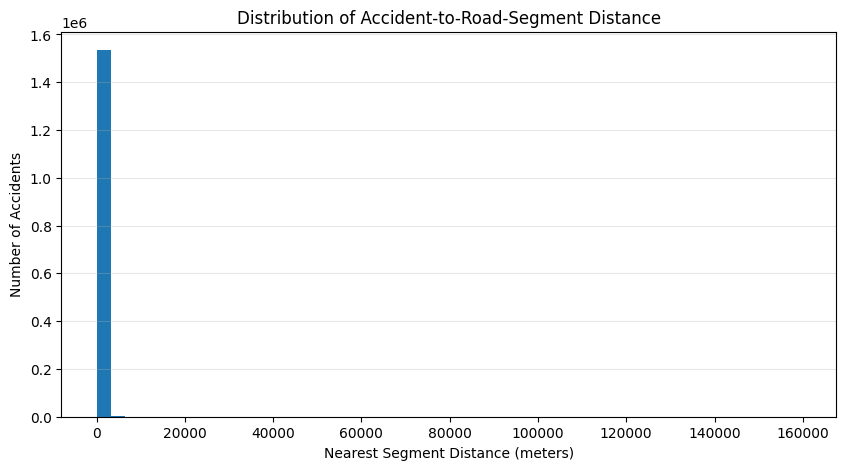

In [31]:
# ============================================
# PHASE 4 — STEP 30
# SPATIAL MATCH VALIDATION
# ============================================

print("========== SPATIAL MATCH VALIDATION ==========")

distance_stats = (
    accident_overlap["DISTANCE_METERS"]
    .describe()
)

display(distance_stats)

print("\nMedian distance:",
      accident_overlap["DISTANCE_METERS"].median())

print(
    "\nMatches within 50 meters:",
    (
        accident_overlap["DISTANCE_METERS"] <= 50
    ).sum()
)

print(
    "Matches within 100 meters:",
    (
        accident_overlap["DISTANCE_METERS"] <= 100
    ).sum()
)

print(
    "Matches within 200 meters:",
    (
        accident_overlap["DISTANCE_METERS"] <= 200
    ).sum()
)

print(
    "Matches beyond 500 meters:",
    (
        accident_overlap["DISTANCE_METERS"] > 500
    ).sum()
)

# Distance distribution
plt.figure(figsize=(10, 5))

plt.hist(
    accident_overlap["DISTANCE_METERS"],
    bins=50
)

plt.xlabel("Nearest Segment Distance (meters)")
plt.ylabel("Number of Accidents")
plt.title("Distribution of Accident-to-Road-Segment Distance")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [32]:
# ============================================
# PHASE 4 — STEP 30A
# DETAILED SPATIAL MATCH QUALITY
# ============================================

print("========== DETAILED SPATIAL MATCH QUALITY ==========")

distance = accident_overlap["DISTANCE_METERS"]

thresholds = [50, 100, 200, 500, 1000, 2000, 5000, 10000]

for threshold in thresholds:
    count = (distance <= threshold).sum()
    percentage = count / len(distance) * 100

    print(
        f"Within {threshold:>5} m: "
        f"{count:>8,} "
        f"({percentage:.2f}%)"
    )

print("\nBeyond 10 km:",
      (distance > 10000).sum())

print(
    "Beyond 50 km:",
    (distance > 50000).sum()
)

print(
    "Beyond 100 km:",
    (distance > 100000).sum()
)

========== DETAILED SPATIAL MATCH QUALITY ==========
Within    50 m:   92,872 (6.05%)
Within   100 m:  259,547 (16.90%)
Within   200 m:  677,653 (44.12%)
Within   500 m: 1,151,686 (74.98%)
Within  1000 m: 1,442,261 (93.90%)
Within  2000 m: 1,526,397 (99.38%)
Within  5000 m: 1,535,774 (99.99%)
Within 10000 m: 1,535,944 (100.00%)

Beyond 10 km: 19
Beyond 50 km: 17
Beyond 100 km: 9


In [33]:
# ============================================
# PHASE 4 — STEP 30B
# INSPECT EXTREME MATCHES
# ============================================

print("========== EXTREME SPATIAL MATCHES ==========")

large_matches = (
    accident_overlap
    .sort_values(
        "DISTANCE_METERS",
        ascending=False
    )
    [
        [
            "COLLISION_ID",
            "CRASH_DATE_DT",
            "LATITUDE",
            "LONGITUDE",
            "SegmentID",
            "DISTANCE_METERS"
        ]
    ]
    .head(20)
)

display(large_matches)

========== EXTREME SPATIAL MATCHES ==========


,COLLISION_ID,CRASH_DATE_DT,LATITUDE,LONGITUDE,SegmentID,DISTANCE_METERS
1142985,3425492,2016-03-20,41.347960,-73.969650,81445.0,159637.719705
916827,3650157,2017-04-13,40.560600,-74.742000,94.0,138283.389326
858265,3690234,2017-06-11,40.560600,-74.742000,94.0,138283.389326
921979,3628215,2017-03-08,40.560600,-74.742000,94.0,138283.389326
891530,3667901,2017-05-10,40.560600,-74.742000,94.0,138283.389326
704024,3833107,2018-01-09,40.560600,-74.742000,94.0,138283.389326
704017,3828137,2018-01-13,40.560600,-74.742000,94.0,138283.389326
634300,3929785,2018-06-26,40.560600,-74.742000,94.0,138283.389326
1141924,3414001,2016-03-27,41.258785,-73.990240,81445.0,128368.108020
845877,3719109,2017-07-26,41.126150,-73.713530,89528.0,88250.962656


In [34]:
# ============================================
# PHASE 4 — STEP 31
# APPLY SPATIAL MATCHING THRESHOLD
# ============================================

print("========== SPATIAL MATCH FILTER ==========")

SPATIAL_THRESHOLD = 2000  # meters

before_filter = len(accident_overlap)

accident_spatial = accident_overlap[
    accident_overlap["DISTANCE_METERS"] <= SPATIAL_THRESHOLD
].copy()

after_filter = len(accident_spatial)

removed = before_filter - after_filter

print("Spatial threshold:", SPATIAL_THRESHOLD, "meters")

print("\nRecords before filtering:",
      before_filter)

print("Records retained:",
      after_filter)

print("Records removed:",
      removed)

print(
    "Percentage retained:",
    round(after_filter / before_filter * 100, 2),
    "%"
)

print(
    "Percentage removed:",
    round(removed / before_filter * 100, 2),
    "%"
)

print("\nFinal distance statistics:")

display(
    accident_spatial["DISTANCE_METERS"].describe()
)

========== SPATIAL MATCH FILTER ==========
Spatial threshold: 2000 meters

Records before filtering: 1535963
Records retained: 1526397
Records removed: 9566
Percentage retained: 99.38 %
Percentage removed: 0.62 %

Final distance statistics:


,DISTANCE_METERS
count,1.526397e+06
mean,3.583516e+02
std,3.288549e+02
min,7.179921e-02
25%,1.273084e+02
50%,2.432905e+02
75%,4.922694e+02
max,1.999799e+03


In [35]:
# ============================================
# PHASE 4 — STEP 32
# PREPARE TRAFFIC DATE/TIME KEY
# ============================================

print("========== PREPARING TRAFFIC TIME KEY ==========")

traffic_df["TRAFFIC_DATE"] = (
    traffic_df["TRAFFIC_DATETIME"]
    .dt.date
)

traffic_df["TRAFFIC_HOUR"] = (
    traffic_df["TRAFFIC_DATETIME"]
    .dt.hour
)

print("Traffic date range:",
      traffic_df["TRAFFIC_DATE"].min(),
      "to",
      traffic_df["TRAFFIC_DATE"].max())

print("Traffic hour range:",
      traffic_df["TRAFFIC_HOUR"].min(),
      "to",
      traffic_df["TRAFFIC_HOUR"].max())

display(
    traffic_df[
        [
            "SegmentID",
            "TRAFFIC_DATETIME",
            "TRAFFIC_DATE",
            "TRAFFIC_HOUR",
            "Vol"
        ]
    ].head(10)
)

========== PREPARING TRAFFIC TIME KEY ==========
Traffic date range: <dask_expr.expr.Scalar: expr=Assign(frame=Assign(frame=Assign(frame=Assign(frame=ArrowStringConversion(frame=FromMapProjectable(0998e35))))))['TRAFFIC_DATE'].min(), dtype=object> to <dask_expr.expr.Scalar: expr=Assign(frame=Assign(frame=Assign(frame=Assign(frame=ArrowStringConversion(frame=FromMapProjectable(0998e35))))))['TRAFFIC_DATE'].max(), dtype=object>
Traffic hour range: <dask_expr.expr.Scalar: expr=Assign(frame=Assign(frame=Assign(frame=Assign(frame=ArrowStringConversion(frame=FromMapProjectable(0998e35))))))['TRAFFIC_HOUR'].min(), dtype=int64> to <dask_expr.expr.Scalar: expr=Assign(frame=Assign(frame=Assign(frame=Assign(frame=ArrowStringConversion(frame=FromMapProjectable(0998e35))))))['TRAFFIC_HOUR'].max(), dtype=int64>


,SegmentID,TRAFFIC_DATETIME,TRAFFIC_DATE,TRAFFIC_HOUR,Vol
0,171896.0,2015-06-23 23:30:00,2015-06-23,23,9.0
1,9896.0,2015-09-14 04:15:00,2015-09-14,4,6.0
2,77817.0,2017-10-19 04:30:00,2017-10-19,4,85.0
3,188023.0,2017-11-07 18:30:00,2017-11-07,18,168.0
4,137516.0,2017-11-03 22:00:00,2017-11-03,22,355.0
5,86053.0,2017-06-17 01:45:00,2017-06-17,1,11.0
6,70683.0,2009-09-01 18:30:00,2009-09-01,18,99.0
7,101101.0,2016-03-21 09:45:00,2016-03-21,9,232.0
8,147877.0,2020-11-14 02:15:00,2020-11-14,2,18.0
9,85935.0,2017-06-22 04:30:00,2017-06-22,4,2.0


In [36]:
# ============================================
# PHASE 4 — STEP 33
# FILTER TRAFFIC TO ACCIDENT-TRAFFIC OVERLAP
# ============================================

print("========== TRAFFIC OVERLAP FILTER ==========")

traffic_overlap = traffic_df[
    (traffic_df["TRAFFIC_DATETIME"] >= "2012-07-01") &
    (traffic_df["TRAFFIC_DATETIME"] <= "2020-12-31 23:59:59")
].copy()

print(
    "Traffic records in overlap period:",
    traffic_overlap.shape[0].compute()
)

print(
    "Overlap starts:",
    traffic_overlap["TRAFFIC_DATETIME"].min().compute()
)

print(
    "Overlap ends:",
    traffic_overlap["TRAFFIC_DATETIME"].max().compute()
)

========== TRAFFIC OVERLAP FILTER ==========
Traffic records in overlap period: 22236107
Overlap starts: 2012-07-01 00:00:00
Overlap ends: 2020-11-22 23:45:00


In [37]:
# ============================================
# PHASE 4 — STEP 34
# HOURLY TRAFFIC AGGREGATION
# ============================================

print("========== HOURLY TRAFFIC AGGREGATION ==========")

traffic_hourly = (
    traffic_overlap
    .dropna(subset=["Vol"])
    .groupby(
        [
            "SegmentID",
            "TRAFFIC_DATE",
            "TRAFFIC_HOUR"
        ]
    )
    .agg(
        Traffic_Volume=("Vol", "sum"),
        Traffic_Observations=("Vol", "count")
    )
    .reset_index()
)

traffic_hourly = traffic_hourly.compute()

print(
    "Hourly traffic records:",
    len(traffic_hourly)
)

print(
    "Unique SegmentIDs:",
    traffic_hourly["SegmentID"].nunique()
)

display(
    traffic_hourly.head(10)
)

========== HOURLY TRAFFIC AGGREGATION ==========
Hourly traffic records: 4409935
Unique SegmentIDs: 12568


,SegmentID,TRAFFIC_DATE,TRAFFIC_HOUR,Traffic_Volume,Traffic_Observations
0,38369.0,2019-02-16,11,120.0,8
1,67713.0,2017-05-18,7,123.0,4
2,194239.0,2019-03-20,1,32.0,4
3,95879.0,2015-05-18,7,3698.0,4
4,91078.0,2017-06-18,4,92.0,8
5,22855.0,2013-04-18,20,283.0,4
6,76787.0,2015-06-11,2,159.0,4
7,101295.0,2018-06-20,12,159.0,8
8,159230.0,2012-10-21,18,492.0,4
9,43257.0,2016-06-06,22,431.0,4


In [38]:
# ============================================
# PHASE 4 — STEP 35
# VALIDATE TRAFFIC MATCHING KEY
# ============================================

print("========== TRAFFIC KEY VALIDATION ==========")

duplicate_keys = traffic_hourly.duplicated(
    subset=[
        "SegmentID",
        "TRAFFIC_DATE",
        "TRAFFIC_HOUR"
    ]
).sum()

unique_keys = traffic_hourly[
    [
        "SegmentID",
        "TRAFFIC_DATE",
        "TRAFFIC_HOUR"
    ]
].drop_duplicates().shape[0]

print(
    "Duplicate SegmentID + Date + Hour keys:",
    duplicate_keys
)

print(
    "Total hourly traffic records:",
    len(traffic_hourly)
)

print(
    "Unique hourly traffic keys:",
    unique_keys
)

print("\nTraffic volume statistics:")

display(
    traffic_hourly["Traffic_Volume"].describe()
)

========== TRAFFIC KEY VALIDATION ==========
Duplicate SegmentID + Date + Hour keys: 0
Total hourly traffic records: 4409935
Unique hourly traffic keys: 4409935

Traffic volume statistics:


,Traffic_Volume
count,4.409935e+06
mean,5.407398e+02
std,7.396600e+02
min,0.000000e+00
25%,1.020000e+02
50%,3.020000e+02
75%,6.850000e+02
max,3.277200e+04


In [39]:
# ============================================
# PHASE 4 — STEP 36
# ACTUAL ACCIDENT + TRAFFIC MERGE
# ============================================

print("========== ACCIDENT + TRAFFIC INTEGRATION ==========")

# Prepare accident date key
accident_spatial["ACCIDENT_DATE_KEY"] = (
    pd.to_datetime(
        accident_spatial["CRASH_DATE_DT"]
    ).dt.date
)

# Create useful time features
accident_spatial["ACCIDENT_DAY_OF_WEEK"] = (
    pd.to_datetime(
        accident_spatial["CRASH_DATE_DT"]
    ).dt.day_name()
)

accident_spatial["ACCIDENT_MONTH"] = (
    pd.to_datetime(
        accident_spatial["CRASH_DATE_DT"]
    ).dt.month
)

# Make sure SegmentID has the same type
accident_spatial["SegmentID"] = (
    pd.to_numeric(
        accident_spatial["SegmentID"],
        errors="coerce"
    ).astype("Int64")
)

traffic_hourly["SegmentID"] = (
    pd.to_numeric(
        traffic_hourly["SegmentID"],
        errors="coerce"
    ).astype("Int64")
)

# Actual merge
integrated_df = accident_spatial.merge(
    traffic_hourly,
    left_on=[
        "SegmentID",
        "ACCIDENT_DATE_KEY",
        "ACCIDENT_HOUR"
    ],
    right_on=[
        "SegmentID",
        "TRAFFIC_DATE",
        "TRAFFIC_HOUR"
    ],
    how="left"
)

print("Accident records before merge:",
      len(accident_spatial))

print("Integrated records after merge:",
      len(integrated_df))

print(
    "Traffic volume matched:",
    integrated_df["Traffic_Volume"].notna().sum()
)

print(
    "Traffic volume not matched:",
    integrated_df["Traffic_Volume"].isna().sum()
)

========== ACCIDENT + TRAFFIC INTEGRATION ==========
Accident records before merge: 1526397
Integrated records after merge: 1526397
Traffic volume matched: 6432
Traffic volume not matched: 1519965


In [40]:
# ============================================
# PHASE 4 — STEP 37
# INTEGRATION VALIDATION
# ============================================

print("========== INTEGRATION VALIDATION ==========")

total_accidents = len(integrated_df)

matched_traffic = (
    integrated_df["Traffic_Volume"]
    .notna()
    .sum()
)

unmatched_traffic = (
    integrated_df["Traffic_Volume"]
    .isna()
    .sum()
)

match_percentage = (
    matched_traffic / total_accidents * 100
)

print("Total integrated accident records:",
      total_accidents)

print("Accidents with traffic data:",
      matched_traffic)

print("Accidents without traffic data:",
      unmatched_traffic)

print(
    "Traffic match rate:",
    round(match_percentage, 2),
    "%"
)

print("\nTraffic volume statistics:")

display(
    integrated_df["Traffic_Volume"].describe()
)

print("\nSample integrated records:")

display(
    integrated_df[
        [
            "COLLISION_ID",
            "CRASH_DATE_DT",
            "ACCIDENT_HOUR",
            "LATITUDE",
            "LONGITUDE",
            "SegmentID",
            "DISTANCE_METERS",
            "Traffic_Volume",
            "Traffic_Observations"
        ]
    ].head(10)
)

========== INTEGRATION VALIDATION ==========
Total integrated accident records: 1526397
Accidents with traffic data: 6432
Accidents without traffic data: 1519965
Traffic match rate: 0.42 %

Traffic volume statistics:


,Traffic_Volume
count,6432.000000
mean,748.474192
std,765.972222
min,0.000000
25%,242.000000
50%,542.000000
75%,1008.000000
max,7684.000000



Sample integrated records:


,COLLISION_ID,CRASH_DATE_DT,ACCIDENT_HOUR,LATITUDE,LONGITUDE,SegmentID,DISTANCE_METERS,Traffic_Volume,Traffic_Observations
0,4136992,2019-05-21,22,40.697540,-73.98312,24470,322.158247,NaN,NaN
1,4408059,2016-04-16,14,40.586277,-73.98620,161596,559.377502,NaN,NaN
2,4407790,2020-04-15,15,40.671585,-73.99843,22088,77.841411,NaN,NaN
3,4408571,2019-04-17,0,40.651974,-73.86542,252280,104.533958,NaN,NaN
4,4408441,2020-04-17,1,40.771610,-73.99046,34307,128.770571,NaN,NaN
5,4345591,2020-09-06,18,40.771038,-73.83413,259445,38.622668,NaN,NaN
6,4411325,2020-04-21,16,40.877796,-73.86806,87609,60.789465,NaN,NaN
7,4485338,2020-12-11,1,40.846657,-73.85944,86336,117.669472,NaN,NaN
8,4412513,2020-05-02,17,40.673760,-73.79473,58806,115.466948,NaN,NaN
9,4412425,2020-12-08,15,40.696570,-73.95844,30670,470.674905,NaN,NaN


In [41]:
print("========== CHECK COLUMNS ==========")

print("Integrated columns:")
print(integrated_df.columns.tolist())

print("\nAccident spatial columns:")
print(accident_spatial.columns.tolist())

========== CHECK COLUMNS ==========
Integrated columns:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5', 'CRASH_DATE_DT', 'ACCIDENT_HOUR', 'ACCIDENT_YEAR', 'SegmentID', 'DISTANCE_METERS', 'ACCIDENT_DATE_KEY', 'ACCIDENT_DAY_OF_WEEK', 'ACCIDENT_MONTH', 'TRAFFIC_DATE', 'TRAFFIC_HOUR', 'Traffic_Volume', 'Traffic_Observations']

Accident spatial columns:
['CRASH DATE', '

In [42]:
# ==========================================
# PHASE 5 — FINAL COLUMN STANDARDIZATION
# ==========================================

print("========== STANDARDIZING FINAL COLUMNS ==========")

integrated_df = integrated_df.rename(columns={
    "NUMBER OF PERSONS INJURED": "NUMBER_OF_PERSONS_INJURED",
    "NUMBER OF PERSONS KILLED": "NUMBER_OF_PERSONS_KILLED"
})

print("Columns renamed successfully.")

print(
    "NUMBER_OF_PERSONS_INJURED" in integrated_df.columns,
    "NUMBER_OF_PERSONS_KILLED" in integrated_df.columns
)

========== STANDARDIZING FINAL COLUMNS ==========
Columns renamed successfully.
True True


In [43]:
# ============================================================
# PHASE 5 — STEP 38
# FINAL INTEGRATED DATASET
# ============================================================

print("========== PHASE 5 — FINAL INTEGRATED DATASET ==========")

# ------------------------------------------------------------
# STEP 38A — STANDARDIZE COLUMN NAMES
# ------------------------------------------------------------

integrated_df = integrated_df.rename(columns={
    "NUMBER OF PERSONS INJURED": "NUMBER_OF_PERSONS_INJURED",
    "NUMBER OF PERSONS KILLED": "NUMBER_OF_PERSONS_KILLED"
})

print("Column names standardized.")


# ------------------------------------------------------------
# STEP 38B — DEFINE FINAL COLUMNS
# ------------------------------------------------------------

final_columns = [
    # Accident identification
    "COLLISION_ID",

    # Accident date/time
    "CRASH DATE",
    "CRASH TIME",
    "CRASH_DATE_DT",
    "ACCIDENT_YEAR",
    "ACCIDENT_MONTH",
    "ACCIDENT_DAY_OF_WEEK",
    "ACCIDENT_HOUR",

    # Accident location
    "BOROUGH",
    "ZIP CODE",
    "LATITUDE",
    "LONGITUDE",
    "LOCATION",
    "ON STREET NAME",
    "CROSS STREET NAME",
    "OFF STREET NAME",

    # Accident severity
    "NUMBER_OF_PERSONS_INJURED",
    "NUMBER_OF_PERSONS_KILLED",
    "NUMBER OF PEDESTRIANS INJURED",
    "NUMBER OF PEDESTRIANS KILLED",
    "NUMBER OF CYCLIST INJURED",
    "NUMBER OF CYCLIST KILLED",
    "NUMBER OF MOTORIST INJURED",
    "NUMBER OF MOTORIST KILLED",

    # Accident contributing factors
    "CONTRIBUTING FACTOR VEHICLE 1",
    "CONTRIBUTING FACTOR VEHICLE 2",
    "CONTRIBUTING FACTOR VEHICLE 3",
    "CONTRIBUTING FACTOR VEHICLE 4",
    "CONTRIBUTING FACTOR VEHICLE 5",

    # Vehicle information
    "VEHICLE TYPE CODE 1",
    "VEHICLE TYPE CODE 2",
    "VEHICLE TYPE CODE 3",
    "VEHICLE TYPE CODE 4",
    "VEHICLE TYPE CODE 5",

    # Spatial integration
    "SegmentID",
    "DISTANCE_METERS",

    # Accident–traffic temporal key
    "ACCIDENT_DATE_KEY",
    "TRAFFIC_DATE",
    "TRAFFIC_HOUR",

    # Traffic information
    "Traffic_Volume",
    "Traffic_Observations"
]


# ------------------------------------------------------------
# STEP 38C — CHECK WHETHER ANY REQUIRED COLUMN IS MISSING
# ------------------------------------------------------------

missing_final_columns = [
    col for col in final_columns
    if col not in integrated_df.columns
]

print("\nMissing final columns:")

if len(missing_final_columns) == 0:
    print("None")
else:
    print(missing_final_columns)


# ------------------------------------------------------------
# STEP 38D — CREATE FINAL DATASET
# ------------------------------------------------------------

if len(missing_final_columns) == 0:

    final_integrated_df = integrated_df[
        final_columns
    ].copy()

    print("\n========== FINAL DATASET CREATED ==========")

    print(
        "Final shape:",
        final_integrated_df.shape
    )

    print(
        "Final rows:",
        len(final_integrated_df)
    )

    print(
        "Final columns:",
        len(final_integrated_df.columns)
    )

    print("\nFinal column list:")

    for i, col in enumerate(final_integrated_df.columns, start=1):
        print(f"{i}. {col}")

else:

    print(
        "\nERROR: Final dataset cannot be created because "
        "some required columns are missing."
    )

========== PHASE 5 — FINAL INTEGRATED DATASET ==========
Column names standardized.

Missing final columns:
None

========== FINAL DATASET CREATED ==========
Final shape: (1526397, 41)
Final rows: 1526397
Final columns: 41

Final column list:
1. COLLISION_ID
2. CRASH DATE
3. CRASH TIME
4. CRASH_DATE_DT
5. ACCIDENT_YEAR
6. ACCIDENT_MONTH
7. ACCIDENT_DAY_OF_WEEK
8. ACCIDENT_HOUR
9. BOROUGH
10. ZIP CODE
11. LATITUDE
12. LONGITUDE
13. LOCATION
14. ON STREET NAME
15. CROSS STREET NAME
16. OFF STREET NAME
17. NUMBER_OF_PERSONS_INJURED
18. NUMBER_OF_PERSONS_KILLED
19. NUMBER OF PEDESTRIANS INJURED
20. NUMBER OF PEDESTRIANS KILLED
21. NUMBER OF CYCLIST INJURED
22. NUMBER OF CYCLIST KILLED
23. NUMBER OF MOTORIST INJURED
24. NUMBER OF MOTORIST KILLED
25. CONTRIBUTING FACTOR VEHICLE 1
26. CONTRIBUTING FACTOR VEHICLE 2
27. CONTRIBUTING FACTOR VEHICLE 3
28. CONTRIBUTING FACTOR VEHICLE 4
29. CONTRIBUTING FACTOR VEHICLE 5
30. VEHICLE TYPE CODE 1
31. VEHICLE TYPE CODE 2
32. VEHICLE TYPE CODE 3
33. VEH

In [44]:
# ============================================================
# PHASE 5 — STEP 39
# FINAL INTEGRATED DATASET VALIDATION + SAVE
# ============================================================

print("========== FINAL INTEGRATED DATASET VALIDATION ==========")

# ------------------------------------------------------------
# 1. Basic shape
# ------------------------------------------------------------

print("Rows:", len(final_integrated_df))
print("Columns:", len(final_integrated_df.columns))


# ------------------------------------------------------------
# 2. Duplicate accident check
# ------------------------------------------------------------

duplicate_collisions = (
    final_integrated_df["COLLISION_ID"]
    .duplicated()
    .sum()
)

print(
    "\nDuplicate COLLISION_ID:",
    duplicate_collisions
)


# ------------------------------------------------------------
# 3. Missing traffic information
# ------------------------------------------------------------

missing_traffic_volume = (
    final_integrated_df["Traffic_Volume"]
    .isna()
    .sum()
)

print(
    "Missing Traffic_Volume:",
    missing_traffic_volume
)

print(
    "Traffic_Volume available:",
    final_integrated_df["Traffic_Volume"]
    .notna()
    .sum()
)


# ------------------------------------------------------------
# 4. Spatial distance validation
# ------------------------------------------------------------

print("\nSpatial distance check:")

print(
    "Minimum distance:",
    final_integrated_df["DISTANCE_METERS"].min()
)

print(
    "Median distance:",
    final_integrated_df["DISTANCE_METERS"].median()
)

print(
    "Maximum distance:",
    final_integrated_df["DISTANCE_METERS"].max()
)

print(
    "Records beyond 2 km:",
    (
        final_integrated_df["DISTANCE_METERS"] > 2000
    ).sum()
)


# ------------------------------------------------------------
# 5. Date validation
# ------------------------------------------------------------

print("\nDate range:")

print(
    final_integrated_df["CRASH_DATE_DT"].min(),
    "to",
    final_integrated_df["CRASH_DATE_DT"].max()
)


# ------------------------------------------------------------
# 6. Traffic volume validation
# ------------------------------------------------------------

print("\nTraffic volume validation:")

print(
    "Negative traffic volumes:",
    (
        final_integrated_df["Traffic_Volume"] < 0
    ).sum()
)


# ------------------------------------------------------------
# 7. Final sample
# ------------------------------------------------------------

print("\nFinal dataset sample:")

display(
    final_integrated_df.head(10)
)


# ------------------------------------------------------------
# 8. Save final integrated dataset
# ------------------------------------------------------------

output_path = (
    "/content/UrbanRisk_AI_Integrated_Dataset.csv"
)

final_integrated_df.to_csv(
    output_path,
    index=False
)

print(
    "\n========== DATASET SAVED =========="
)

print(
    "File:",
    output_path
)

========== FINAL INTEGRATED DATASET VALIDATION ==========
Rows: 1526397
Columns: 41

Duplicate COLLISION_ID: 0
Missing Traffic_Volume: 1519965
Traffic_Volume available: 6432

Spatial distance check:
Minimum distance: 0.07179920565262402
Median distance: 243.29051768756148
Maximum distance: 1999.7985038040883
Records beyond 2 km: 0

Date range:
2012-07-01 00:00:00 to 2020-12-31 00:00:00

Traffic volume validation:
Negative traffic volumes: 0

Final dataset sample:


,COLLISION_ID,CRASH DATE,CRASH TIME,CRASH_DATE_DT,ACCIDENT_YEAR,ACCIDENT_MONTH,ACCIDENT_DAY_OF_WEEK,ACCIDENT_HOUR,BOROUGH,ZIP CODE,...,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5,SegmentID,DISTANCE_METERS,ACCIDENT_DATE_KEY,TRAFFIC_DATE,TRAFFIC_HOUR,Traffic_Volume,Traffic_Observations
0,4136992,05/21/2019,22:50,2019-05-21,2019,5,Tuesday,22,BROOKLYN,11201,...,NaN,NaN,NaN,24470,322.158247,2019-05-21,NaN,NaN,NaN,NaN
1,4408059,04/16/2016,14:20,2016-04-16,2016,4,Saturday,14,BROOKLYN,11214,...,NaN,NaN,NaN,161596,559.377502,2016-04-16,NaN,NaN,NaN,NaN
2,4407790,04/15/2020,15:20,2020-04-15,2020,4,Wednesday,15,NaN,NaN,...,NaN,NaN,NaN,22088,77.841411,2020-04-15,NaN,NaN,NaN,NaN
3,4408571,04/17/2019,0:49,2019-04-17,2019,4,Wednesday,0,NaN,NaN,...,NaN,NaN,NaN,252280,104.533958,2019-04-17,NaN,NaN,NaN,NaN
4,4408441,04/17/2020,1:50,2020-04-17,2020,4,Friday,1,MANHATTAN,10019,...,NaN,NaN,NaN,34307,128.770571,2020-04-17,NaN,NaN,NaN,NaN
5,4345591,09/06/2020,18:05,2020-09-06,2020,9,Sunday,18,NaN,NaN,...,NaN,NaN,NaN,259445,38.622668,2020-09-06,NaN,NaN,NaN,NaN
6,4411325,04/21/2020,16:40,2020-04-21,2020,4,Tuesday,16,NaN,NaN,...,NaN,NaN,NaN,87609,60.789465,2020-04-21,NaN,NaN,NaN,NaN
7,4485338,12/11/2020,1:45,2020-12-11,2020,12,Friday,1,BRONX,10462,...,NaN,NaN,NaN,86336,117.669472,2020-12-11,NaN,NaN,NaN,NaN
8,4412513,05/02/2020,17:30,2020-05-02,2020,5,Saturday,17,QUEENS,11436,...,NaN,NaN,NaN,58806,115.466948,2020-05-02,NaN,NaN,NaN,NaN
9,4412425,12/08/2020,15:18,2020-12-08,2020,12,Tuesday,15,NaN,NaN,...,NaN,NaN,NaN,30670,470.674905,2020-12-08,NaN,NaN,NaN,NaN



========== DATASET SAVED ==========
File: /content/UrbanRisk_AI_Integrated_Dataset.csv


In [45]:
from google.colab import files

files.download(
    "/content/UrbanRisk_AI_Integrated_Dataset.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
# ============================================
# PHASE 5 — EDA
# STEP 40 — LOAD FINAL INTEGRATED DATASET
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("========== PHASE 5 — EDA ==========")

integrated_file = "/content/UrbanRisk_AI_Integrated_Dataset.csv"

eda_df = pd.read_csv(integrated_file)

print("Dataset loaded successfully!")

print("\nShape:")
print(eda_df.shape)

print("\nColumns:")
print(eda_df.columns.tolist())

print("\nFirst 5 records:")
display(eda_df.head())

========== PHASE 5 — EDA ==========


/tmp/ipykernel_1360/1171774342.py:14: DtypeWarning: Columns (9,37) have mixed types. Specify dtype option on import or set low_memory=False.
  eda_df = pd.read_csv(integrated_file)


Dataset loaded successfully!

Shape:
(1526397, 41)

Columns:
['COLLISION_ID', 'CRASH DATE', 'CRASH TIME', 'CRASH_DATE_DT', 'ACCIDENT_YEAR', 'ACCIDENT_MONTH', 'ACCIDENT_DAY_OF_WEEK', 'ACCIDENT_HOUR', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER_OF_PERSONS_INJURED', 'NUMBER_OF_PERSONS_KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5', 'SegmentID', 'DISTANCE_METERS', 'ACCIDENT_DATE_KEY', 'TRAFFIC_DATE', 'TRAFFIC_HOUR', 'Traffic_Volume', 'Traffic_Observations']

First 5 records:


,COLLISION_ID,CRASH DATE,CRASH TIME,CRASH_DATE_DT,ACCIDENT_YEAR,ACCIDENT_MONTH,ACCIDENT_DAY_OF_WEEK,ACCIDENT_HOUR,BOROUGH,ZIP CODE,...,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5,SegmentID,DISTANCE_METERS,ACCIDENT_DATE_KEY,TRAFFIC_DATE,TRAFFIC_HOUR,Traffic_Volume,Traffic_Observations
0,4136992,05/21/2019,22:50,2019-05-21,2019,5,Tuesday,22,BROOKLYN,11201.0,...,NaN,NaN,NaN,24470,322.158247,2019-05-21,NaN,NaN,NaN,NaN
1,4408059,04/16/2016,14:20,2016-04-16,2016,4,Saturday,14,BROOKLYN,11214.0,...,NaN,NaN,NaN,161596,559.377502,2016-04-16,NaN,NaN,NaN,NaN
2,4407790,04/15/2020,15:20,2020-04-15,2020,4,Wednesday,15,NaN,NaN,...,NaN,NaN,NaN,22088,77.841411,2020-04-15,NaN,NaN,NaN,NaN
3,4408571,04/17/2019,0:49,2019-04-17,2019,4,Wednesday,0,NaN,NaN,...,NaN,NaN,NaN,252280,104.533958,2019-04-17,NaN,NaN,NaN,NaN
4,4408441,04/17/2020,1:50,2020-04-17,2020,4,Friday,1,MANHATTAN,10019.0,...,NaN,NaN,NaN,34307,128.770571,2020-04-17,NaN,NaN,NaN,NaN


In [47]:
# ============================================
# STEP 41 — DATA VERIFICATION
# ============================================

print("========== DATA VERIFICATION ==========")

print("Rows:", len(eda_df))
print("Columns:", len(eda_df.columns))

print("\nData types:")
display(eda_df.dtypes.to_frame("Data Type"))

print("\nMissing values:")

missing_values = (
    eda_df.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_values.to_frame("Missing Count")
)

print("\nDuplicate COLLISION_ID:")

print(
    eda_df["COLLISION_ID"]
    .duplicated()
    .sum()
)

========== DATA VERIFICATION ==========
Rows: 1526397
Columns: 41

Data types:


,Data Type
COLLISION_ID,int64
CRASH DATE,object
CRASH TIME,object
CRASH_DATE_DT,object
ACCIDENT_YEAR,int64
ACCIDENT_MONTH,int64
ACCIDENT_DAY_OF_WEEK,object
ACCIDENT_HOUR,int64
BOROUGH,object
ZIP CODE,object



Missing values:


,Missing Count
VEHICLE TYPE CODE 5,1520775
CONTRIBUTING FACTOR VEHICLE 5,1520631
TRAFFIC_HOUR,1519965
Traffic_Volume,1519965
Traffic_Observations,1519965
TRAFFIC_DATE,1519965
VEHICLE TYPE CODE 4,1505230
CONTRIBUTING FACTOR VEHICLE 4,1504634
VEHICLE TYPE CODE 3,1428290
CONTRIBUTING FACTOR VEHICLE 3,1425572



Duplicate COLLISION_ID:
0


In [48]:
# ============================================
# STEP 42 — DESCRIPTIVE STATISTICS
# ============================================

print("========== DESCRIPTIVE STATISTICS ==========")

numeric_columns = [
    "ACCIDENT_HOUR",
    "ACCIDENT_MONTH",
    "LATITUDE",
    "LONGITUDE",
    "SegmentID",
    "DISTANCE_METERS",
    "Traffic_Volume",
    "Traffic_Observations",
    "NUMBER_OF_PERSONS_INJURED",
    "NUMBER_OF_PERSONS_KILLED",
    "NUMBER OF PEDESTRIANS INJURED",
    "NUMBER OF PEDESTRIANS KILLED",
    "NUMBER OF CYCLIST INJURED",
    "NUMBER OF CYCLIST KILLED",
    "NUMBER OF MOTORIST INJURED",
    "NUMBER OF MOTORIST KILLED"
]

statistics = (
    eda_df[numeric_columns]
    .describe()
    .T
)

statistics["median"] = (
    eda_df[numeric_columns]
    .median()
)

statistics["IQR"] = (
    eda_df[numeric_columns].quantile(0.75)
    -
    eda_df[numeric_columns].quantile(0.25)
)

display(statistics)

========== DESCRIPTIVE STATISTICS ==========


,count,mean,std,min,25%,50%,75%,max,median,IQR
ACCIDENT_HOUR,1526397.0,13.286592,5.645223e+00,0.000000,9.000000,14.000000,18.000000,2.300000e+01,14.000000,9.000000
ACCIDENT_MONTH,1526397.0,6.776628,3.419683e+00,1.000000,4.000000,7.000000,10.000000,1.200000e+01,7.000000,6.000000
LATITUDE,1526397.0,40.724339,7.842689e-02,40.498949,40.668950,40.722282,40.768562,4.091288e+01,40.722282,0.099612
LONGITUDE,1526397.0,-73.920737,8.572675e-02,-74.254532,-73.976199,-73.928889,-73.867429,-7.370055e+01,-73.928889,0.108770
SegmentID,1526397.0,320773.385003,1.414286e+06,94.000000,36248.000000,76254.000000,150181.000000,9.017093e+06,76254.000000,113933.000000
DISTANCE_METERS,1526397.0,358.351592,3.288549e+02,0.071799,127.308442,243.290518,492.269398,1.999799e+03,243.290518,364.960956
Traffic_Volume,6432.0,748.474192,7.659722e+02,0.000000,242.000000,542.000000,1008.000000,7.684000e+03,542.000000,766.000000
Traffic_Observations,6432.0,5.093128,2.108222e+00,1.000000,4.000000,4.000000,8.000000,4.800000e+01,4.000000,4.000000
NUMBER_OF_PERSONS_INJURED,1526382.0,0.272383,6.640340e-01,0.000000,0.000000,0.000000,0.000000,4.300000e+01,0.000000,0.000000
NUMBER_OF_PERSONS_KILLED,1526369.0,0.001232,3.724783e-02,0.000000,0.000000,0.000000,0.000000,8.000000e+00,0.000000,0.000000


========== ACCIDENTS BY HOUR ==========


,Accident Count
ACCIDENT_HOUR,
0,45987
1,24443
2,18593
3,16049
4,18330
5,20212
6,32232
7,44677
8,84929



Peak accident hour: 16:00 → 112183 accidents
Lowest accident hour: 3:00 → 16049 accidents


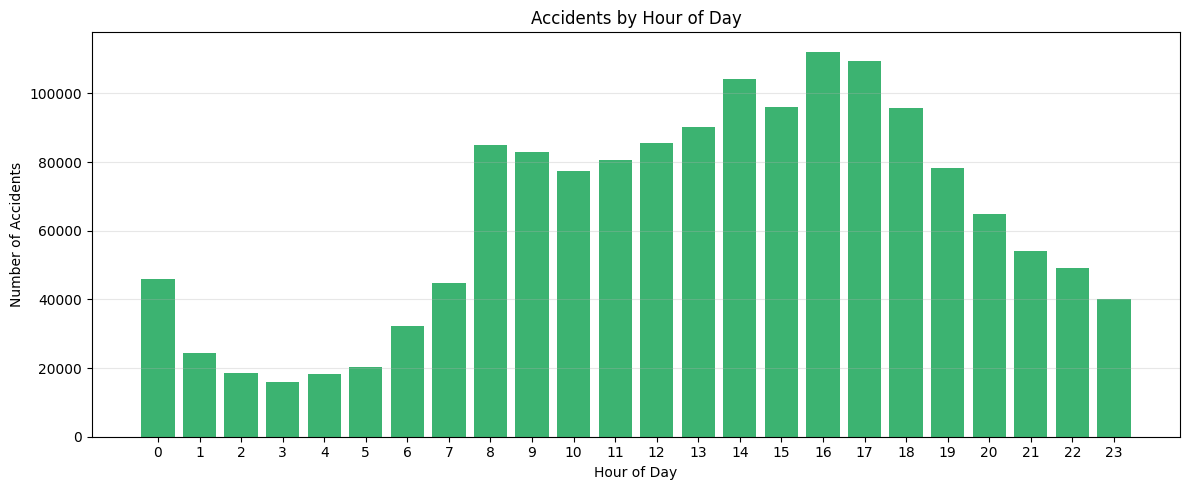

In [49]:
# ============================================
# STEP 43 — ACCIDENTS BY HOUR
# ============================================

print("========== ACCIDENTS BY HOUR ==========")

accidents_by_hour = (
    eda_df["ACCIDENT_HOUR"]
    .value_counts()
    .sort_index()
)

display(
    accidents_by_hour.to_frame("Accident Count")
)

peak_hour = accidents_by_hour.idxmax()
peak_hour_count = accidents_by_hour.max()

lowest_hour = accidents_by_hour.idxmin()
lowest_hour_count = accidents_by_hour.min()

print(
    f"\nPeak accident hour: "
    f"{peak_hour}:00 → {peak_hour_count} accidents"
)

print(
    f"Lowest accident hour: "
    f"{lowest_hour}:00 → {lowest_hour_count} accidents"
)

# Colorful graph
plt.figure(figsize=(12, 5))

plt.bar(
    accidents_by_hour.index,
    accidents_by_hour.values,
    color="mediumseagreen"
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")
plt.title("Accidents by Hour of Day")

plt.xticks(range(24))
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== TRAFFIC VOLUME BY HOUR ==========


,mean,median,sum
ACCIDENT_HOUR,,,
0,564.43,268.0,92002.0
1,396.90,197.5,48422.0
2,360.23,166.0,27738.0
3,257.38,115.0,19561.0
4,302.21,160.5,24781.0
5,360.71,148.0,31382.0
6,649.22,381.0,83750.0
7,904.30,619.0,181764.0
8,797.79,592.5,309542.0



Highest average traffic: 18:00 → 975.13
Lowest average traffic: 3:00 → 257.38


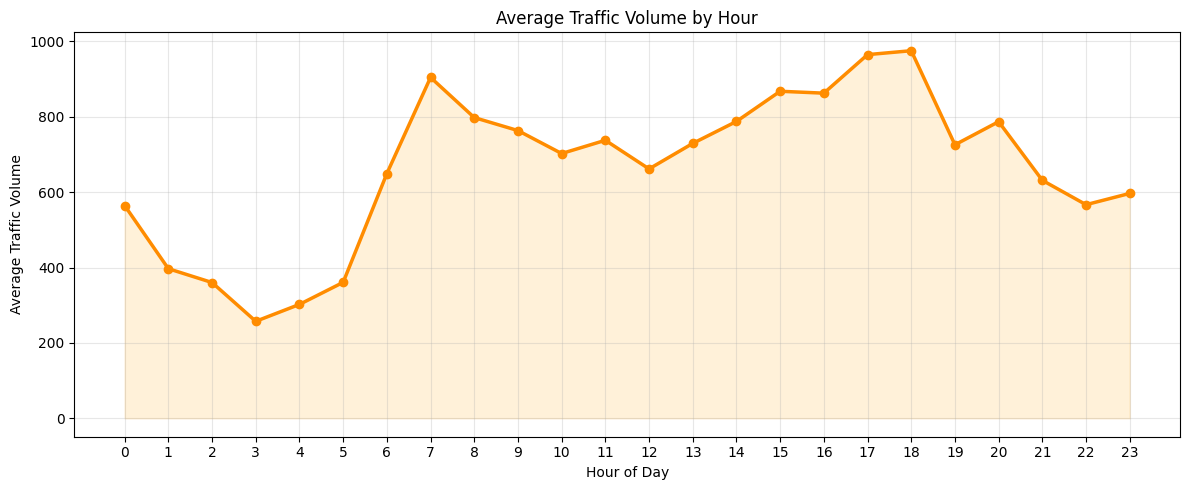

In [50]:
# ============================================
# STEP 44 — TRAFFIC VOLUME BY HOUR
# ============================================

print("========== TRAFFIC VOLUME BY HOUR ==========")

traffic_by_hour = (
    eda_df
    .groupby("ACCIDENT_HOUR")["Traffic_Volume"]
    .agg(["mean", "median", "sum"])
    .round(2)
)

display(traffic_by_hour)

# Peak traffic hour
peak_traffic_hour = traffic_by_hour["mean"].idxmax()
peak_traffic_value = traffic_by_hour["mean"].max()

# Lowest traffic hour
lowest_traffic_hour = traffic_by_hour["mean"].idxmin()
lowest_traffic_value = traffic_by_hour["mean"].min()

print(
    f"\nHighest average traffic: "
    f"{peak_traffic_hour}:00 → {peak_traffic_value:.2f}"
)

print(
    f"Lowest average traffic: "
    f"{lowest_traffic_hour}:00 → {lowest_traffic_value:.2f}"
)

# Colorful graph
plt.figure(figsize=(12, 5))

plt.plot(
    traffic_by_hour.index,
    traffic_by_hour["mean"],
    marker="o",
    linewidth=2.5,
    color="darkorange"
)

plt.fill_between(
    traffic_by_hour.index,
    traffic_by_hour["mean"],
    alpha=0.15,
    color="orange"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.title("Average Traffic Volume by Hour")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

========== ACCIDENTS VS TRAFFIC ==========


,ACCIDENT_HOUR,Accident_Count,Average_Traffic
0,0,45987,564.429448
1,1,24443,396.901639
2,2,18593,360.233766
3,3,16049,257.381579
4,4,18330,302.207317
5,5,20212,360.712644
6,6,32232,649.224806
7,7,44677,904.298507
8,8,84929,797.788660
9,9,83035,763.303763



Correlation matrix:


,Accident_Count,Average_Traffic
Accident_Count,1.00000,0.85338
Average_Traffic,0.85338,1.00000



Accident count vs average traffic correlation: 0.8534


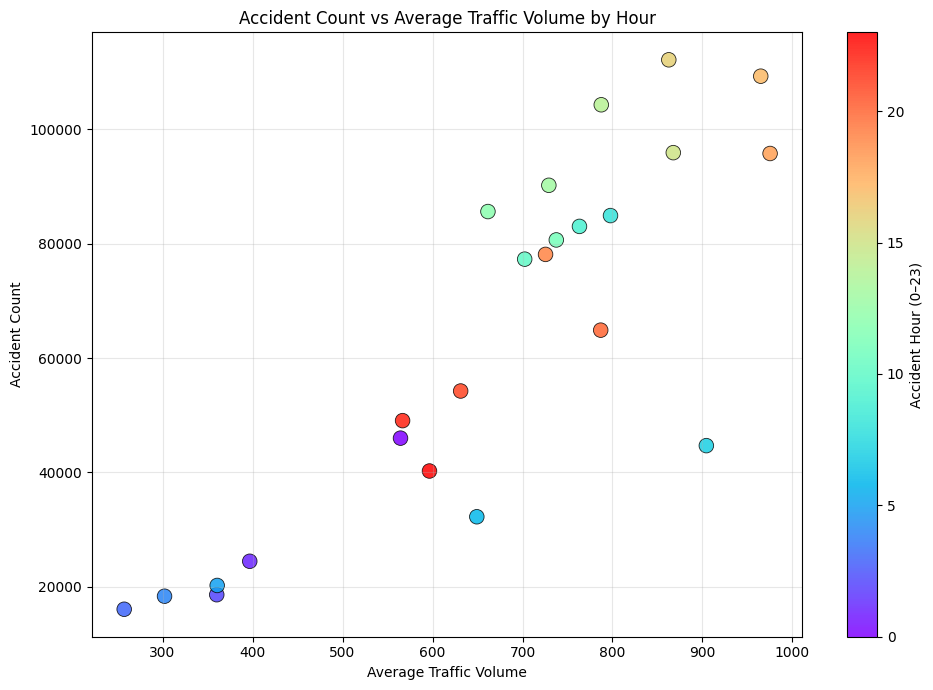

In [51]:
# ============================================
# STEP 45 — ACCIDENTS VS TRAFFIC VOLUME
# ============================================

print("========== ACCIDENTS VS TRAFFIC ==========")

# Create hourly analysis
hourly_analysis = (
    eda_df
    .groupby("ACCIDENT_HOUR")
    .agg(
        Accident_Count=("COLLISION_ID", "count"),
        Average_Traffic=("Traffic_Volume", "mean")
    )
    .reset_index()
)

display(hourly_analysis)

# ============================================
# CORRELATION
# ============================================

hourly_correlation = (
    hourly_analysis[
        [
            "Accident_Count",
            "Average_Traffic"
        ]
    ].corr()
)

print("\nCorrelation matrix:")
display(hourly_correlation)

correlation_value = (
    hourly_correlation.loc[
        "Accident_Count",
        "Average_Traffic"
    ]
)

print(
    "\nAccident count vs average traffic correlation:",
    round(correlation_value, 4)
)

# ============================================
# RAINBOW SCATTER PLOT
# ============================================

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    hourly_analysis["Average_Traffic"],
    hourly_analysis["Accident_Count"],
    s=110,
    c=hourly_analysis["ACCIDENT_HOUR"],
    cmap="rainbow",
    vmin=0,
    vmax=23,
    alpha=0.85,
    edgecolors="black",
    linewidths=0.6
)

plt.xlabel("Average Traffic Volume")
plt.ylabel("Accident Count")
plt.title("Accident Count vs Average Traffic Volume by Hour")

# Colorbar
cbar = plt.colorbar(scatter)
cbar.set_label("Accident Hour (0–23)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

========== ACCIDENTS BY MONTH ==========


,Accident Count
ACCIDENT_MONTH,
1,118260
2,107870
3,116995
4,102131
5,126327
6,127929
7,138085
8,137426
9,137515



Highest accident month: 10 → 141669 accidents
Lowest accident month: 4 → 102131 accidents


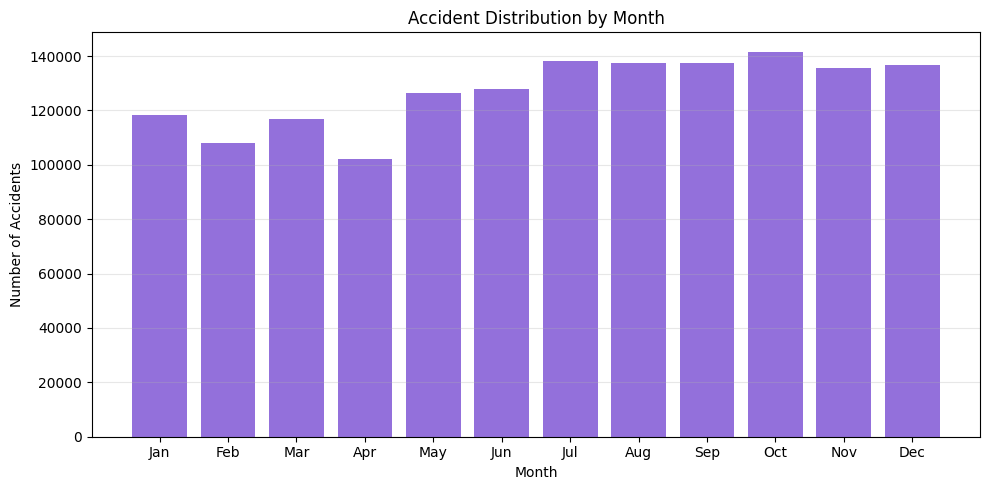

In [52]:
# ============================================
# STEP 46 — ACCIDENTS BY MONTH
# ============================================

print("========== ACCIDENTS BY MONTH ==========")

accidents_by_month = (
    eda_df["ACCIDENT_MONTH"]
    .value_counts()
    .sort_index()
)

display(
    accidents_by_month.to_frame("Accident Count")
)

peak_month = accidents_by_month.idxmax()
peak_month_count = accidents_by_month.max()

lowest_month = accidents_by_month.idxmin()
lowest_month_count = accidents_by_month.min()

print(
    f"\nHighest accident month: "
    f"{peak_month} → {peak_month_count} accidents"
)

print(
    f"Lowest accident month: "
    f"{lowest_month} → {lowest_month_count} accidents"
)

# Colorful graph
plt.figure(figsize=(10, 5))

plt.bar(
    accidents_by_month.index,
    accidents_by_month.values,
    color="mediumpurple"
)

plt.xlabel("Month")
plt.ylabel("Number of Accidents")
plt.title("Accident Distribution by Month")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== ACCIDENTS BY DAY OF WEEK ==========


,Accident Count
ACCIDENT_DAY_OF_WEEK,
Monday,219016
Tuesday,226317
Wednesday,223648
Thursday,229322
Friday,244486
Saturday,203722
Sunday,179886



Highest accident day: Friday → 244486 accidents
Lowest accident day: Sunday → 179886 accidents


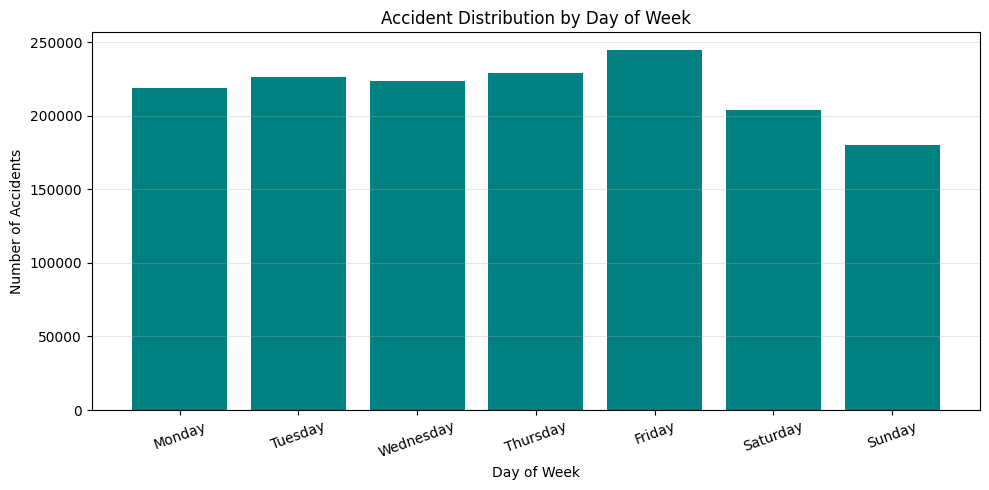

In [53]:
# ============================================
# STEP 47 — ACCIDENTS BY DAY OF WEEK
# ============================================

print("========== ACCIDENTS BY DAY OF WEEK ==========")

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

accidents_by_day = (
    eda_df["ACCIDENT_DAY_OF_WEEK"]
    .value_counts()
    .reindex(day_order)
)

display(
    accidents_by_day.to_frame("Accident Count")
)

peak_day = accidents_by_day.idxmax()
peak_day_count = accidents_by_day.max()

lowest_day = accidents_by_day.idxmin()
lowest_day_count = accidents_by_day.min()

print(
    f"\nHighest accident day: "
    f"{peak_day} → {peak_day_count} accidents"
)

print(
    f"Lowest accident day: "
    f"{lowest_day} → {lowest_day_count} accidents"
)

# Colorful graph
plt.figure(figsize=(10, 5))

plt.bar(
    accidents_by_day.index,
    accidents_by_day.values,
    color="teal"
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Accidents")
plt.title("Accident Distribution by Day of Week")

plt.xticks(rotation=20)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== WEEKDAY VS WEEKEND ==========


,Accident Count
DAY_TYPE,
Weekday,1142789
Weekend,383608



Weekday accidents: 1142789
Weekend accidents: 383608

Percentage distribution:


,Percentage
DAY_TYPE,
Weekday,74.87
Weekend,25.13


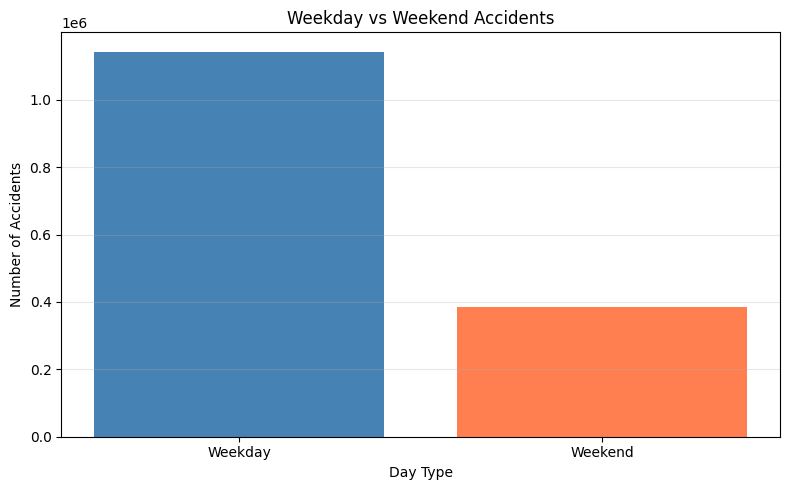

In [54]:
# ============================================
# STEP 48 — WEEKDAY VS WEEKEND
# ============================================

print("========== WEEKDAY VS WEEKEND ==========")

weekday_days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

weekend_days = [
    "Saturday",
    "Sunday"
]

eda_df["DAY_TYPE"] = np.where(
    eda_df["ACCIDENT_DAY_OF_WEEK"].isin(weekday_days),
    "Weekday",
    "Weekend"
)

accidents_by_day_type = (
    eda_df["DAY_TYPE"]
    .value_counts()
    .reindex(["Weekday", "Weekend"])
)

display(
    accidents_by_day_type.to_frame("Accident Count")
)

print(
    "\nWeekday accidents:",
    accidents_by_day_type["Weekday"]
)

print(
    "Weekend accidents:",
    accidents_by_day_type["Weekend"]
)

# Percentage
day_type_percentage = (
    accidents_by_day_type
    / accidents_by_day_type.sum()
    * 100
)

print("\nPercentage distribution:")

display(
    day_type_percentage
    .round(2)
    .to_frame("Percentage")
)

# Graph
plt.figure(figsize=(8, 5))

plt.bar(
    accidents_by_day_type.index,
    accidents_by_day_type.values,
    color=["steelblue", "coral"]
)

plt.xlabel("Day Type")
plt.ylabel("Number of Accidents")
plt.title("Weekday vs Weekend Accidents")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== ACCIDENT SPATIAL DISTRIBUTION ==========
Valid accident coordinates: 1526397
Points used for plotting: 200000


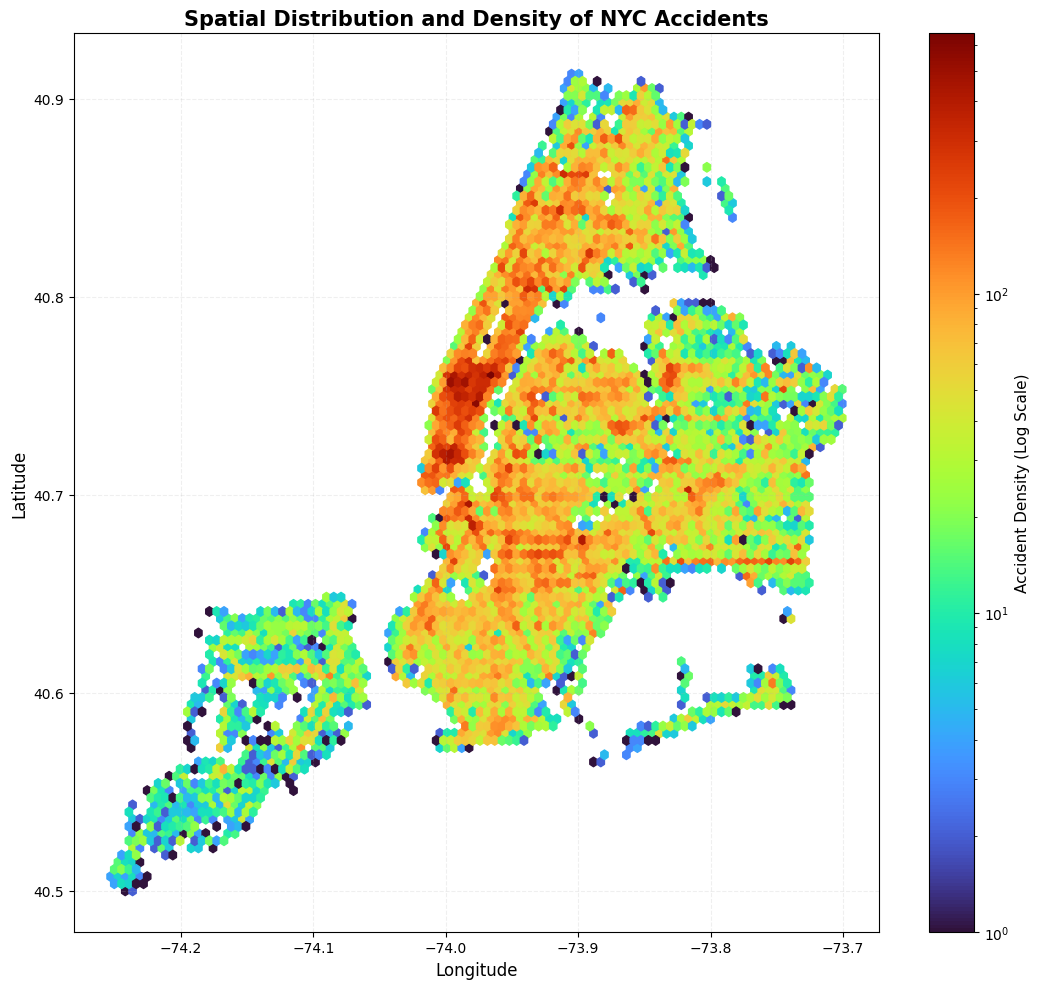

In [55]:
# ============================================
# STEP 49 — ACCIDENT SPATIAL DISTRIBUTION
# ============================================

print("========== ACCIDENT SPATIAL DISTRIBUTION ==========")

# --------------------------------------------
# STEP 1 — CHECK REQUIRED COLUMNS
# --------------------------------------------

required_columns = ["LATITUDE", "LONGITUDE"]

missing_columns = [
    col for col in required_columns
    if col not in eda_df.columns
]

if missing_columns:
    print("ERROR: Missing columns:", missing_columns)

else:

    # --------------------------------------------
    # STEP 2 — SELECT VALID COORDINATES
    # --------------------------------------------

    spatial_sample = (
        eda_df[
            ["LATITUDE", "LONGITUDE"]
        ]
        .dropna()
        .copy()
    )

    # Remove invalid geographic coordinates
    spatial_sample = spatial_sample[
        (spatial_sample["LATITUDE"].between(-90, 90)) &
        (spatial_sample["LONGITUDE"].between(-180, 180))
    ]

    print(
        "Valid accident coordinates:",
        len(spatial_sample)
    )

    # --------------------------------------------
    # STEP 3 — SAMPLE FOR FASTER PLOTTING
    # --------------------------------------------

    if len(spatial_sample) > 200000:

        spatial_sample = spatial_sample.sample(
            n=200000,
            random_state=42
        )

    print(
        "Points used for plotting:",
        len(spatial_sample)
    )

    # --------------------------------------------
    # STEP 4 — HEXBIN SPATIAL DENSITY PLOT
    # --------------------------------------------

    plt.figure(figsize=(11, 10))

    hb = plt.hexbin(
        spatial_sample["LONGITUDE"],
        spatial_sample["LATITUDE"],
        gridsize=100,
        cmap="turbo",
        mincnt=1,
        bins="log"
    )

    # --------------------------------------------
    # STEP 5 — LABELS
    # --------------------------------------------

    plt.xlabel(
        "Longitude",
        fontsize=12
    )

    plt.ylabel(
        "Latitude",
        fontsize=12
    )

    plt.title(
        "Spatial Distribution and Density of NYC Accidents",
        fontsize=15,
        fontweight="bold"
    )

    # --------------------------------------------
    # STEP 6 — COLORBAR
    # --------------------------------------------

    cbar = plt.colorbar(hb)

    cbar.set_label(
        "Accident Density (Log Scale)",
        fontsize=11
    )

    # --------------------------------------------
    # STEP 7 — GRID
    # --------------------------------------------

    plt.grid(
        alpha=0.2,
        linestyle="--"
    )

    # --------------------------------------------
    # STEP 8 — FINAL DISPLAY
    # --------------------------------------------

    plt.tight_layout()

    plt.show()

========== ACCIDENT-TO-ROAD DISTANCE ==========


,DISTANCE_METERS
count,1.526397e+06
mean,3.583516e+02
std,3.288549e+02
min,7.179921e-02
25%,1.273084e+02
50%,2.432905e+02
75%,4.922694e+02
max,1.999799e+03



Median distance: 243.29 meters
Mean distance: 358.35 meters


,Accident Count
DISTANCE_METERS,
0–50 m,92872
50–100 m,166675
100–200 m,418106
200–500 m,474033
500–1000 m,290575
1000–2000 m,84136


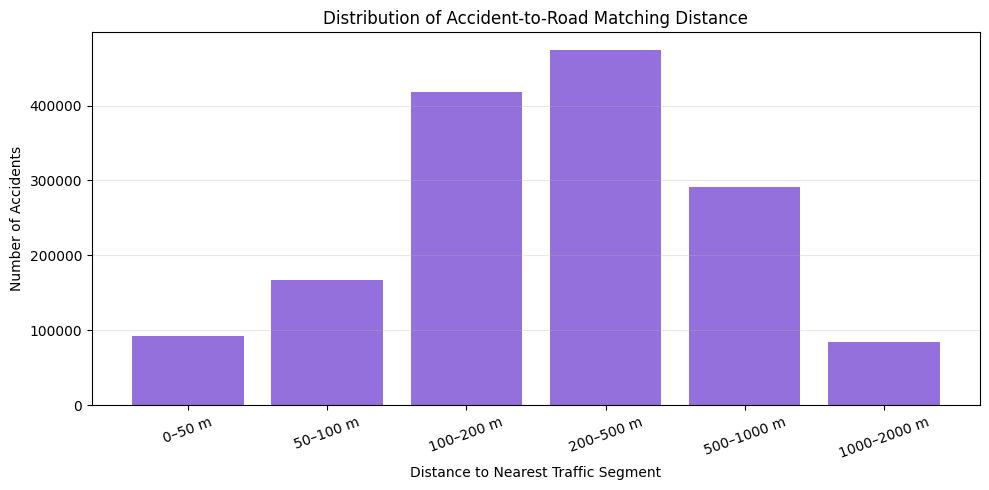

In [56]:
# ============================================
# STEP 50 — ACCIDENT TO ROAD DISTANCE
# ============================================

print("========== ACCIDENT-TO-ROAD DISTANCE ==========")

distance_stats = (
    eda_df["DISTANCE_METERS"]
    .describe()
)

display(distance_stats)

print(
    "\nMedian distance:",
    round(
        eda_df["DISTANCE_METERS"].median(),
        2
    ),
    "meters"
)

print(
    "Mean distance:",
    round(
        eda_df["DISTANCE_METERS"].mean(),
        2
    ),
    "meters"
)

# Distance categories
distance_categories = pd.cut(
    eda_df["DISTANCE_METERS"],
    bins=[
        0,
        50,
        100,
        200,
        500,
        1000,
        2000
    ],
    labels=[
        "0–50 m",
        "50–100 m",
        "100–200 m",
        "200–500 m",
        "500–1000 m",
        "1000–2000 m"
    ],
    include_lowest=True
)

distance_distribution = (
    distance_categories
    .value_counts()
    .sort_index()
)

display(
    distance_distribution.to_frame(
        "Accident Count"
    )
)

# Graph
plt.figure(figsize=(10, 5))

plt.bar(
    distance_distribution.index.astype(str),
    distance_distribution.values,
    color="mediumpurple"
)

plt.xlabel("Distance to Nearest Traffic Segment")
plt.ylabel("Number of Accidents")
plt.title(
    "Distribution of Accident-to-Road Matching Distance"
)

plt.xticks(rotation=20)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== ACCIDENT HEATMAP ==========

Accident frequency by day and hour:


ACCIDENT_HOUR,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
ACCIDENT_DAY_OF_WEEK,,,,,,,,,,,,,,,,,,,,,
Monday,5848,2752,1919,1544,1891,2642,5235,7613,14681,13809,...,14823,14026,16685,16131,13605,10603,8369,6632,5672,4424
Tuesday,5205,2166,1511,1183,1341,2334,5197,7858,15260,14723,...,15437,14271,17141,16942,14599,11535,9109,7210,6172,4996
Wednesday,5406,2409,1551,1323,1497,2267,4866,7787,14786,13530,...,15599,14486,16804,16958,14982,11665,9189,7614,6603,5061
Thursday,5859,2522,1842,1439,1666,2389,4989,7562,14921,14121,...,15397,14402,17005,17072,14622,11810,9723,8095,7138,5600
Friday,6721,3229,2365,1838,2121,2632,5233,7517,14427,13861,...,16806,15861,18124,18043,15582,12755,10676,8764,8257,7284
Saturday,8456,5413,4526,4082,4569,3763,3542,3512,6274,7555,...,13728,11877,13927,12807,11894,10502,9573,8688,8521,7646
Sunday,8492,5952,4879,4640,5245,4185,3170,2828,4580,5436,...,12526,11015,12497,11363,10506,9267,8242,7230,6687,5226


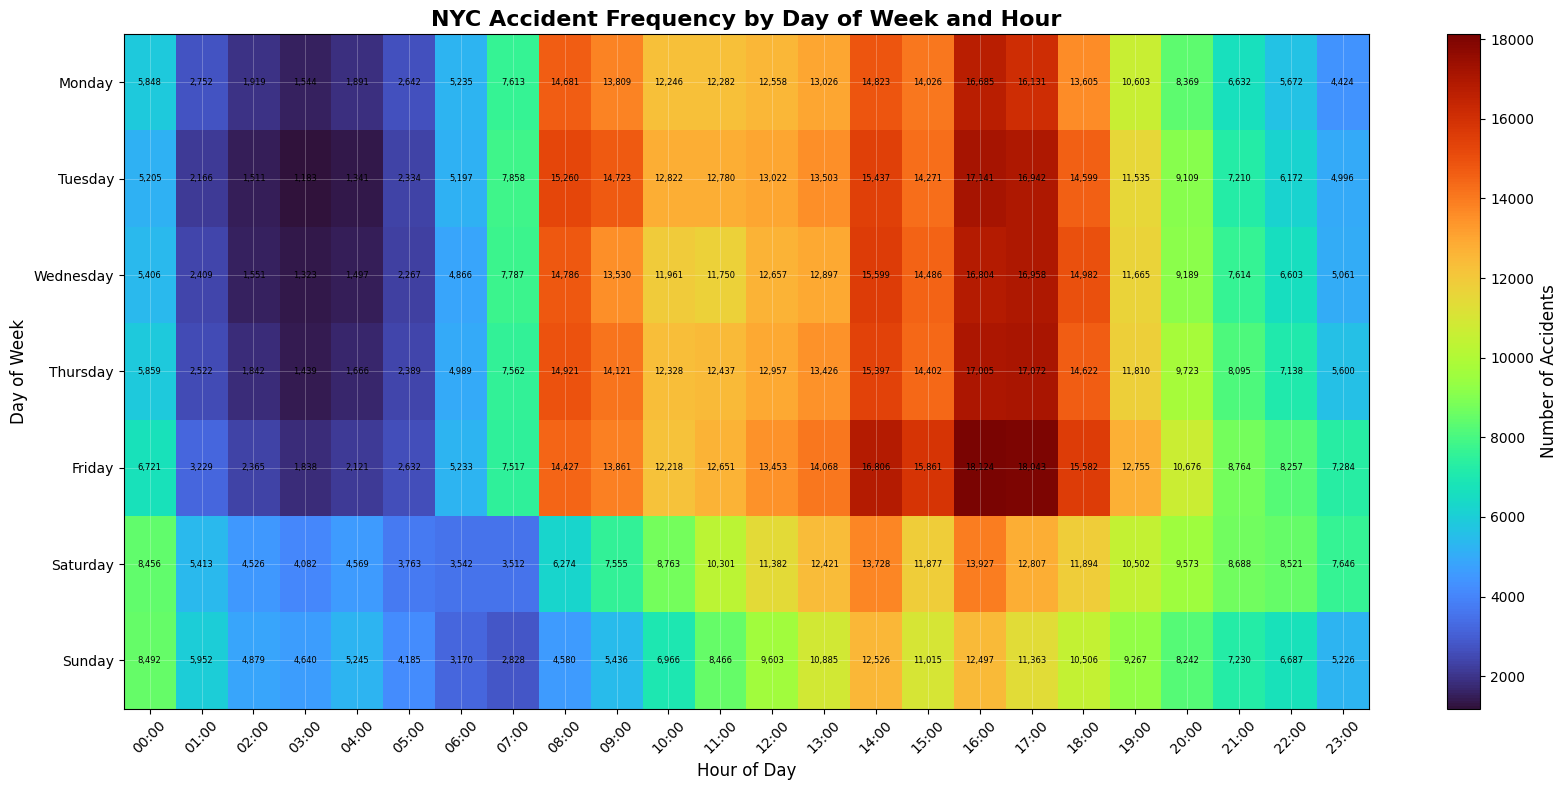

In [57]:
# ============================================
# STEP 51 — ACCIDENT HEATMAP
# ============================================

print("========== ACCIDENT HEATMAP ==========")

# --------------------------------------------
# STEP 1 — DEFINE DAY ORDER
# --------------------------------------------

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# --------------------------------------------
# STEP 2 — CHECK REQUIRED COLUMNS
# --------------------------------------------

required_columns = [
    "ACCIDENT_DAY_OF_WEEK",
    "ACCIDENT_HOUR",
    "COLLISION_ID"
]

missing_columns = [
    col for col in required_columns
    if col not in eda_df.columns
]

if missing_columns:

    print(
        "ERROR: Missing columns:",
        missing_columns
    )

else:

    # ----------------------------------------
    # STEP 3 — CREATE DAY-HOUR TABLE
    # ----------------------------------------

    heatmap_data = (
        eda_df
        .pivot_table(
            index="ACCIDENT_DAY_OF_WEEK",
            columns="ACCIDENT_HOUR",
            values="COLLISION_ID",
            aggfunc="count",
            fill_value=0
        )
        .reindex(day_order)
    )

    # ----------------------------------------
    # STEP 4 — ENSURE ALL 24 HOURS EXIST
    # ----------------------------------------

    heatmap_data = heatmap_data.reindex(
        columns=range(24),
        fill_value=0
    )

    print("\nAccident frequency by day and hour:")

    display(heatmap_data)

    # ----------------------------------------
    # STEP 5 — CREATE HEATMAP
    # ----------------------------------------

    plt.figure(figsize=(17, 8))

    heatmap_plot = plt.imshow(
        heatmap_data,
        aspect="auto",
        cmap="turbo",
        interpolation="nearest"
    )

    # ----------------------------------------
    # STEP 6 — COLORBAR
    # ----------------------------------------

    cbar = plt.colorbar(
        heatmap_plot
    )

    cbar.set_label(
        "Number of Accidents",
        fontsize=12
    )

    # ----------------------------------------
    # STEP 7 — X AXIS
    # ----------------------------------------

    plt.xticks(
        range(24),
        [
            f"{hour:02d}:00"
            for hour in range(24)
        ],
        rotation=45
    )

    # ----------------------------------------
    # STEP 8 — Y AXIS
    # ----------------------------------------

    plt.yticks(
        range(7),
        day_order
    )

    # ----------------------------------------
    # STEP 9 — LABELS
    # ----------------------------------------

    plt.xlabel(
        "Hour of Day",
        fontsize=12
    )

    plt.ylabel(
        "Day of Week",
        fontsize=12
    )

    plt.title(
        "NYC Accident Frequency by Day of Week and Hour",
        fontsize=16,
        fontweight="bold"
    )

    # ----------------------------------------
    # STEP 10 — ADD VALUES TO CELLS
    # ----------------------------------------

    for i in range(heatmap_data.shape[0]):

        for j in range(heatmap_data.shape[1]):

            value = heatmap_data.iloc[i, j]

            if value > 0:

                plt.text(
                    j,
                    i,
                    f"{int(value):,}",
                    ha="center",
                    va="center",
                    fontsize=6
                )

    # ----------------------------------------
    # STEP 11 — GRID
    # ----------------------------------------

    plt.grid(
        visible=True,
        color="white",
        linewidth=0.5,
        alpha=0.35
    )

    # ----------------------------------------
    # STEP 12 — DISPLAY
    # ----------------------------------------

    plt.tight_layout()

    plt.show()

========== TRAFFIC VOLUME DISTRIBUTION ==========


,Traffic_Volume
count,6432.000000
mean,748.474192
std,765.972222
min,0.000000
25%,242.000000
50%,542.000000
75%,1008.000000
max,7684.000000



Median traffic volume: 542.0
Mean traffic volume: 748.47
Maximum traffic volume: 7684.0


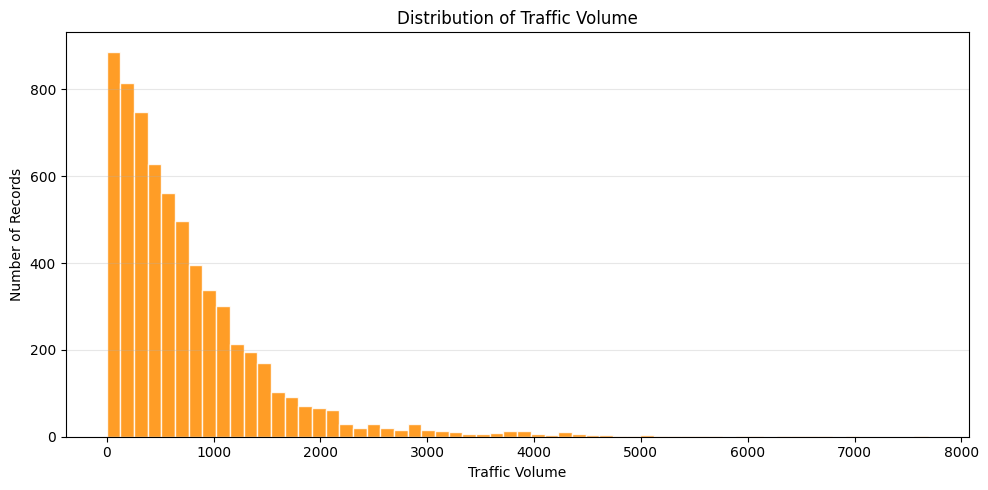

In [58]:
# ============================================
# STEP 52 — TRAFFIC VOLUME DISTRIBUTION
# ============================================

print("========== TRAFFIC VOLUME DISTRIBUTION ==========")

traffic_stats = eda_df["Traffic_Volume"].describe()

display(traffic_stats)

print(
    "\nMedian traffic volume:",
    eda_df["Traffic_Volume"].median()
)

print(
    "Mean traffic volume:",
    round(
        eda_df["Traffic_Volume"].mean(),
        2
    )
)

print(
    "Maximum traffic volume:",
    eda_df["Traffic_Volume"].max()
)

# Histogram
plt.figure(figsize=(10, 5))

plt.hist(
    eda_df["Traffic_Volume"].dropna(),
    bins=60,
    color="darkorange",
    edgecolor="white",
    alpha=0.85
)

plt.xlabel("Traffic Volume")
plt.ylabel("Number of Records")
plt.title("Distribution of Traffic Volume")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== CORRELATION ANALYSIS ==========


,ACCIDENT_HOUR,ACCIDENT_MONTH,LATITUDE,LONGITUDE,DISTANCE_METERS,Traffic_Volume,Traffic_Observations,NUMBER_OF_PERSONS_INJURED,NUMBER_OF_PERSONS_KILLED,NUMBER OF PEDESTRIANS INJURED,NUMBER OF PEDESTRIANS KILLED,NUMBER OF CYCLIST INJURED,NUMBER OF CYCLIST KILLED,NUMBER OF MOTORIST INJURED,NUMBER OF MOTORIST KILLED
ACCIDENT_HOUR,1.000000,0.009489,-0.013571,-0.005632,-0.007798,0.088644,0.013268,0.016612,-0.006256,0.028093,-0.001758,0.037953,-0.000893,-0.002422,-0.007375
ACCIDENT_MONTH,0.009489,1.000000,-0.001757,-0.002366,-0.005236,0.034492,0.015479,0.017268,0.002093,0.007197,0.002721,0.021686,0.000356,0.009849,0.000111
LATITUDE,-0.013571,-0.001757,1.000000,0.320323,-0.075857,0.080158,0.029657,-0.015858,-0.001461,0.005696,-0.000399,-0.001558,-0.000908,-0.018676,-0.001331
LONGITUDE,-0.005632,-0.002366,0.320323,1.000000,0.144090,0.016864,0.096417,0.037220,0.003624,-0.011207,0.001286,-0.031678,-0.001617,0.051682,0.004985
DISTANCE_METERS,-0.007798,-0.005236,-0.075857,0.144090,1.000000,-0.065968,0.088167,0.008442,0.000162,-0.016747,-0.002683,-0.019595,-0.002183,0.020162,0.004002
Traffic_Volume,0.088644,0.034492,0.080158,0.016864,-0.065968,1.000000,0.176005,-0.049827,0.006045,-0.028183,0.000546,-0.024028,-0.007725,-0.035366,0.014718
Traffic_Observations,0.013268,0.015479,0.029657,0.096417,0.088167,0.176005,1.000000,-0.003015,0.016976,0.000372,0.003482,0.010708,0.017195,-0.007133,0.016124
NUMBER_OF_PERSONS_INJURED,0.016612,0.017268,-0.015858,0.037220,0.008442,-0.049827,-0.003015,1.000000,0.017932,0.296390,0.004411,0.178490,0.000583,0.905274,0.022433
NUMBER_OF_PERSONS_KILLED,-0.006256,0.002093,-0.001461,0.003624,0.000162,0.006045,0.016976,0.017932,1.000000,0.008936,0.717601,-0.003305,0.283846,0.016226,0.645935
NUMBER OF PEDESTRIANS INJURED,0.028093,0.007197,0.005696,-0.011207,-0.016747,-0.028183,0.000372,0.296390,0.008936,1.000000,0.013937,-0.031116,0.001743,-0.059673,-0.002080


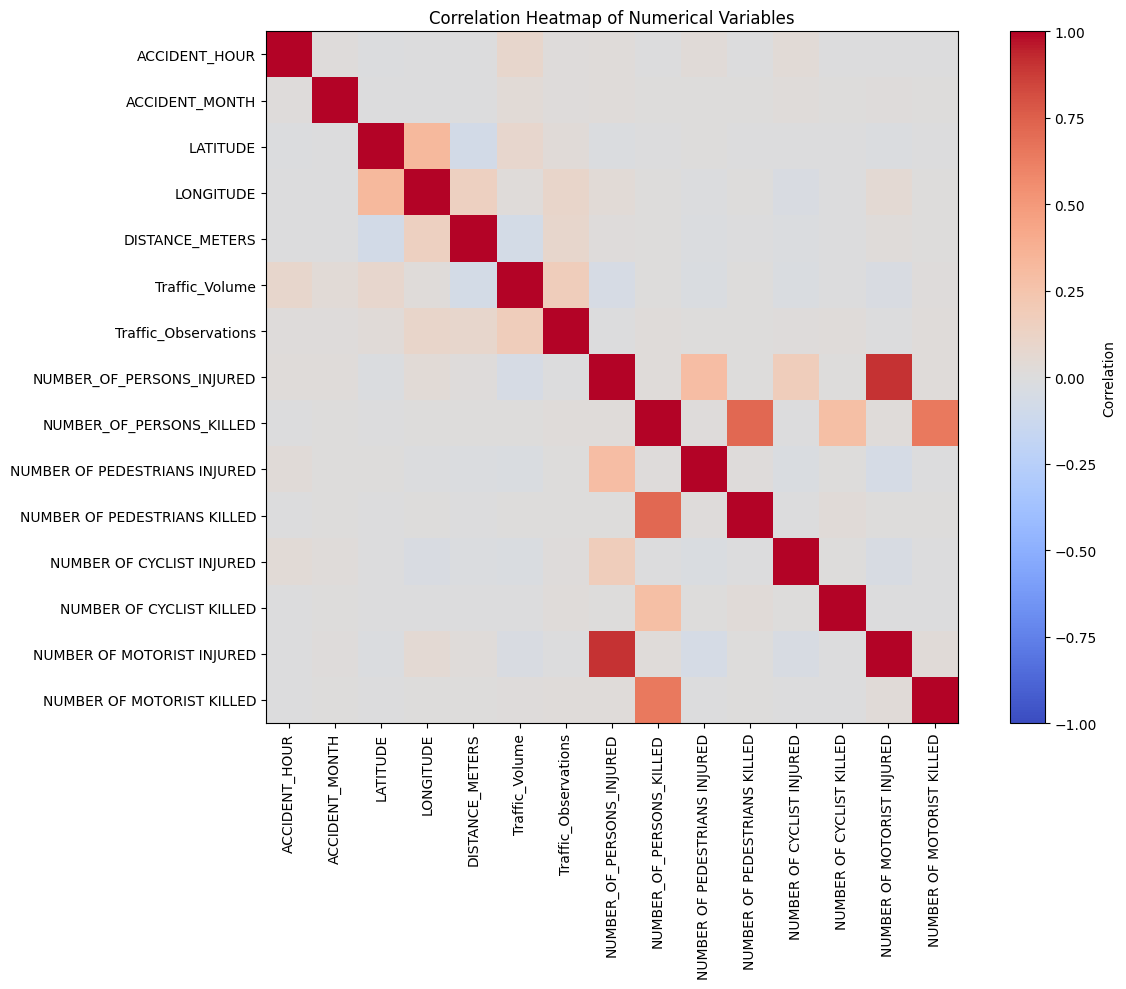

<Figure size 640x480 with 0 Axes>

In [59]:
# ============================================
# STEP 53 — CORRELATION HEATMAP
# ============================================

print("========== CORRELATION ANALYSIS ==========")

correlation_columns = [
    "ACCIDENT_HOUR",
    "ACCIDENT_MONTH",
    "LATITUDE",
    "LONGITUDE",
    "DISTANCE_METERS",
    "Traffic_Volume",
    "Traffic_Observations",
    "NUMBER_OF_PERSONS_INJURED",
    "NUMBER_OF_PERSONS_KILLED",
    "NUMBER OF PEDESTRIANS INJURED",
    "NUMBER OF PEDESTRIANS KILLED",
    "NUMBER OF CYCLIST INJURED",
    "NUMBER OF CYCLIST KILLED",
    "NUMBER OF MOTORIST INJURED",
    "NUMBER OF MOTORIST KILLED"
]

correlation_matrix = (
    eda_df[correlation_columns]
    .corr()
)

display(correlation_matrix)

# Heatmap
plt.figure(figsize=(13, 10))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title(
    "Correlation Heatmap of Numerical Variables"
)

plt.tight_layout()
plt.show()
# Save correlation heatmap
plt.savefig(
    "/content/UrbanRisk_AI_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

========== ACCIDENT SEVERITY ANALYSIS ==========


,Total
Total Injured,415760.0
Total Killed,1880.0
Pedestrians Injured,82520.0
Pedestrians Killed,1008.0
Cyclists Injured,36546.0
Cyclists Killed,144.0
Motorists Injured,296358.0
Motorists Killed,725.0



Accident severity distribution:


,Accident Count
ACCIDENT_SEVERITY,
Property/No Reported Injury,1217742
Injury,306851
Fatal,1804


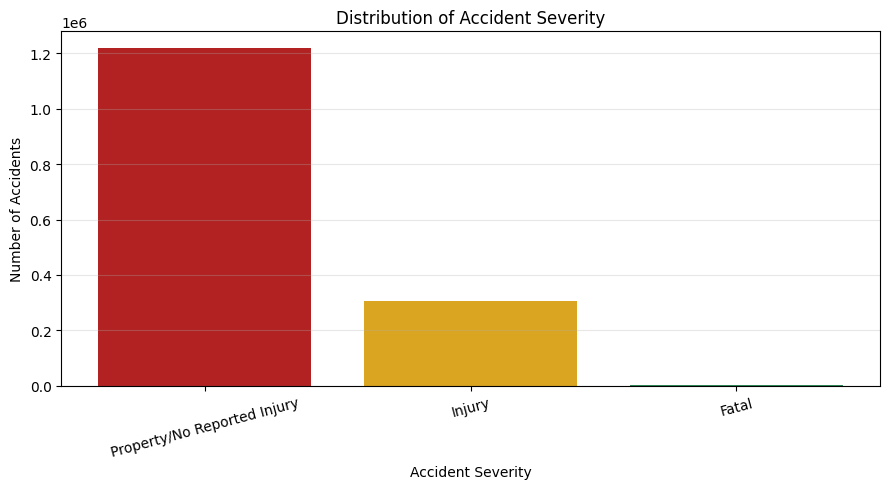

In [60]:
# ============================================
# STEP 54 — ACCIDENT SEVERITY ANALYSIS
# ============================================

print("========== ACCIDENT SEVERITY ANALYSIS ==========")

severity_summary = pd.DataFrame({
    "Total Injured": [
        eda_df["NUMBER_OF_PERSONS_INJURED"].sum()
    ],
    "Total Killed": [
        eda_df["NUMBER_OF_PERSONS_KILLED"].sum()
    ],
    "Pedestrians Injured": [
        eda_df["NUMBER OF PEDESTRIANS INJURED"].sum()
    ],
    "Pedestrians Killed": [
        eda_df["NUMBER OF PEDESTRIANS KILLED"].sum()
    ],
    "Cyclists Injured": [
        eda_df["NUMBER OF CYCLIST INJURED"].sum()
    ],
    "Cyclists Killed": [
        eda_df["NUMBER OF CYCLIST KILLED"].sum()
    ],
    "Motorists Injured": [
        eda_df["NUMBER OF MOTORIST INJURED"].sum()
    ],
    "Motorists Killed": [
        eda_df["NUMBER OF MOTORIST KILLED"].sum()
    ]
})

display(severity_summary.T.rename(
    columns={0: "Total"}
))

# Create severity category
eda_df["ACCIDENT_SEVERITY"] = np.select(
    [
        eda_df["NUMBER_OF_PERSONS_KILLED"] > 0,
        eda_df["NUMBER_OF_PERSONS_INJURED"] > 0
    ],
    [
        "Fatal",
        "Injury"
    ],
    default="Property/No Reported Injury"
)

severity_counts = (
    eda_df["ACCIDENT_SEVERITY"]
    .value_counts()
)

print("\nAccident severity distribution:")

display(
    severity_counts.to_frame("Accident Count")
)

# Graph
plt.figure(figsize=(9, 5))

plt.bar(
    severity_counts.index,
    severity_counts.values,
    color=["firebrick", "goldenrod", "seagreen"]
)

plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.title("Distribution of Accident Severity")

plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== TOP CONTRIBUTING FACTORS ==========
Top 15 contributing factors:


,Accident Count
CONTRIBUTING FACTOR VEHICLE 1,
Unspecified,545047
Driver Inattention/Distraction,297482
Failure to Yield Right-of-Way,90464
Following Too Closely,76392
Backing Unsafely,59956
Other Vehicular,48385
Passing or Lane Usage Improper,38556
Fatigued/Drowsy,37147
Turning Improperly,37145


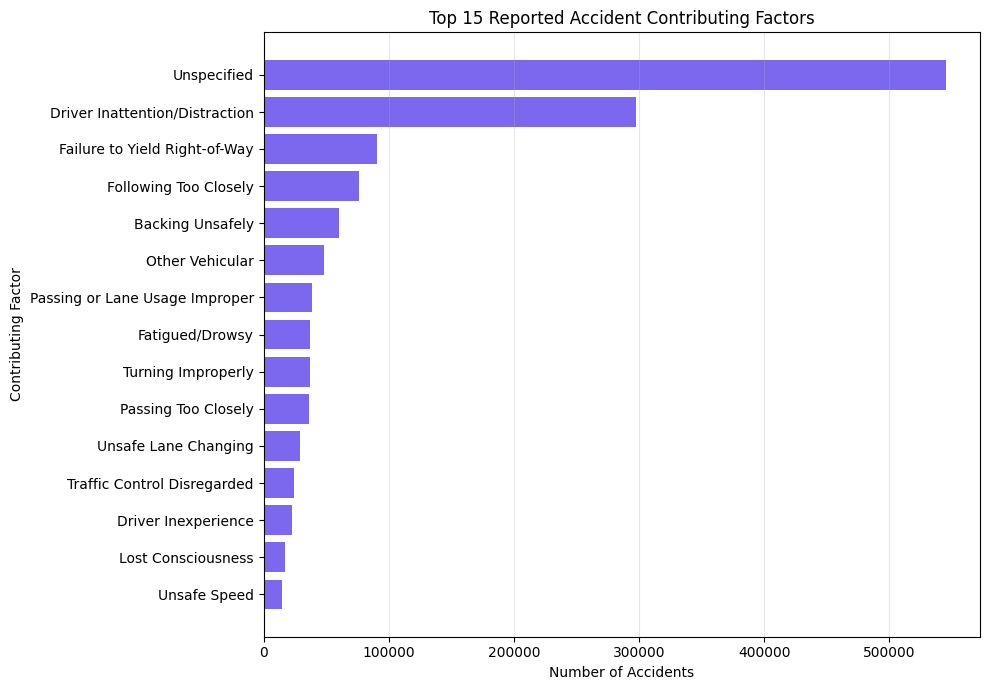

In [61]:
# ============================================
# STEP 55 — TOP CONTRIBUTING FACTORS
# ============================================

print("========== TOP CONTRIBUTING FACTORS ==========")

factor_counts = (
    eda_df[
        "CONTRIBUTING FACTOR VEHICLE 1"
    ]
    .dropna()
    .value_counts()
)

print("Top 15 contributing factors:")

display(
    factor_counts
    .head(15)
    .to_frame("Accident Count")
)

# Graph
top_factors = factor_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))

plt.barh(
    top_factors.index,
    top_factors.values,
    color="mediumslateblue"
)

plt.xlabel("Number of Accidents")
plt.ylabel("Contributing Factor")
plt.title(
    "Top 15 Reported Accident Contributing Factors"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== ACCIDENTS BY BOROUGH ==========


,Accident Count
BOROUGH,
BROOKLYN,369615
QUEENS,313010
MANHATTAN,273775
BRONX,167143
STATEN ISLAND,48614



Highest accident borough:
BROOKLYN → 369615


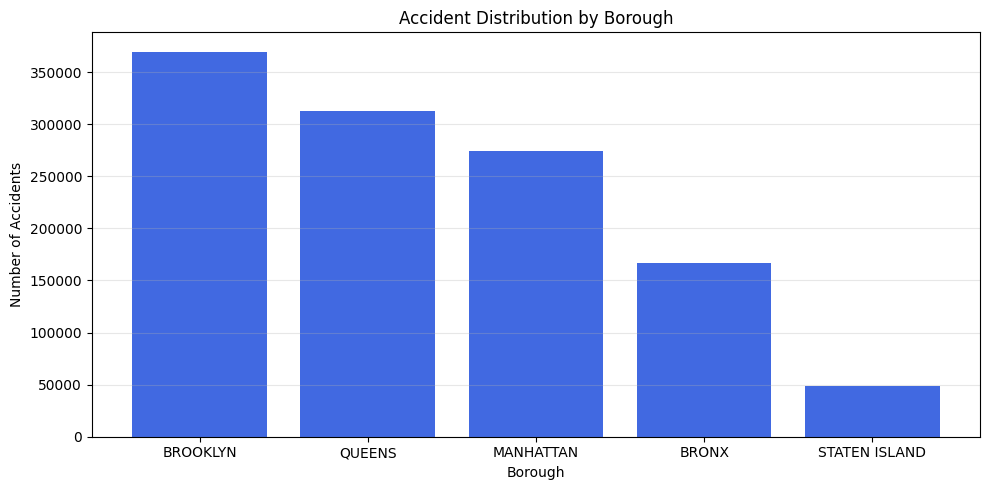

In [62]:
# ============================================
# STEP 56 — ACCIDENTS BY BOROUGH
# ============================================

print("========== ACCIDENTS BY BOROUGH ==========")

borough_counts = (
    eda_df["BOROUGH"]
    .dropna()
    .value_counts()
)

display(
    borough_counts.to_frame("Accident Count")
)

print("\nHighest accident borough:")
print(
    borough_counts.idxmax(),
    "→",
    borough_counts.max()
)

# Graph
plt.figure(figsize=(10, 5))

plt.bar(
    borough_counts.index,
    borough_counts.values,
    color="royalblue"
)

plt.xlabel("Borough")
plt.ylabel("Number of Accidents")
plt.title("Accident Distribution by Borough")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== TRAFFIC VOLUME VS SEVERITY ==========


ACCIDENT_SEVERITY,Fatal,Injury,Property/No Reported Injury
TRAFFIC_LEVEL,,,
Low,3,341,1268
Medium-Low,1,320,1285
Medium-High,3,305,1301
High,3,232,1370



Severity percentage within each traffic level:


ACCIDENT_SEVERITY,Fatal,Injury,Property/No Reported Injury
TRAFFIC_LEVEL,,,
Low,0.19,21.15,78.66
Medium-Low,0.06,19.93,80.01
Medium-High,0.19,18.96,80.86
High,0.19,14.45,85.36


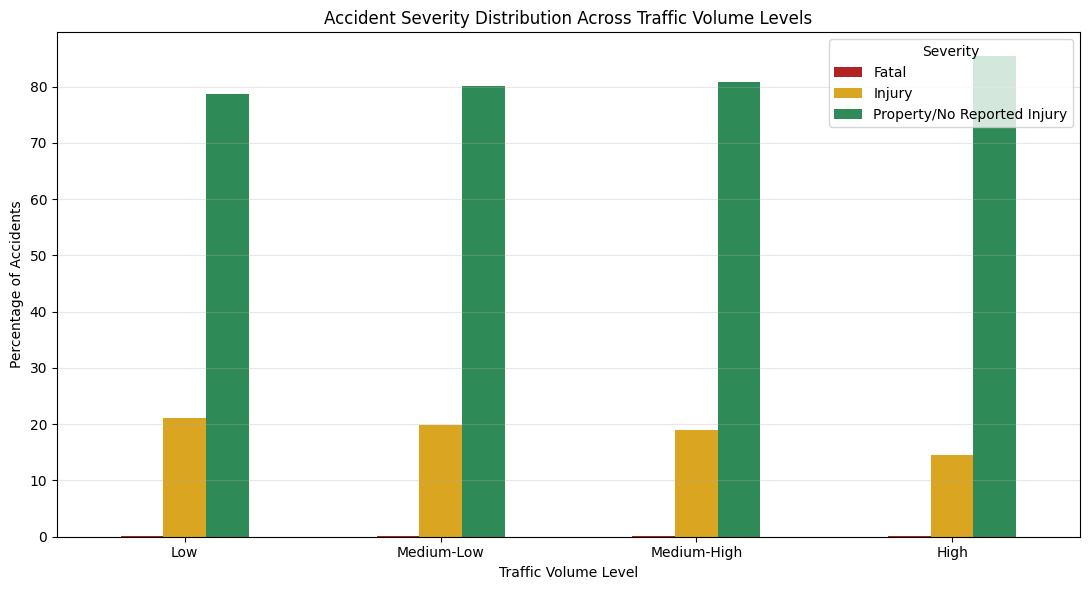

In [63]:
# ============================================
# STEP 57 — TRAFFIC VOLUME VS SEVERITY
# ============================================

print("========== TRAFFIC VOLUME VS SEVERITY ==========")

eda_df["TRAFFIC_LEVEL"] = pd.qcut(
    eda_df["Traffic_Volume"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

severity_traffic = pd.crosstab(
    eda_df["TRAFFIC_LEVEL"],
    eda_df["ACCIDENT_SEVERITY"]
)

display(severity_traffic)

# Convert to percentage
severity_traffic_percentage = (
    severity_traffic
    .div(
        severity_traffic.sum(axis=1),
        axis=0
    )
    * 100
)

print("\nSeverity percentage within each traffic level:")

display(
    severity_traffic_percentage.round(2)
)

# Graph
severity_traffic_percentage.plot(
    kind="bar",
    figsize=(11, 6),
    color=[
        "firebrick",
        "goldenrod",
        "seagreen"
    ]
)

plt.xlabel("Traffic Volume Level")
plt.ylabel("Percentage of Accidents")
plt.title(
    "Accident Severity Distribution Across Traffic Volume Levels"
)

plt.xticks(rotation=0)
plt.legend(title="Severity")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== TOP VEHICLE TYPES ==========
Top 15 vehicle types:


,Accident Count
VEHICLE TYPE CODE 1,
Sedan,389211
PASSENGER VEHICLE,345157
Station Wagon/Sport Utility Vehicle,306413
SPORT UTILITY / STATION WAGON,150055
Taxi,39575
TAXI,29369
4 dr sedan,28255
Pick-up Truck,24930
VAN,21934


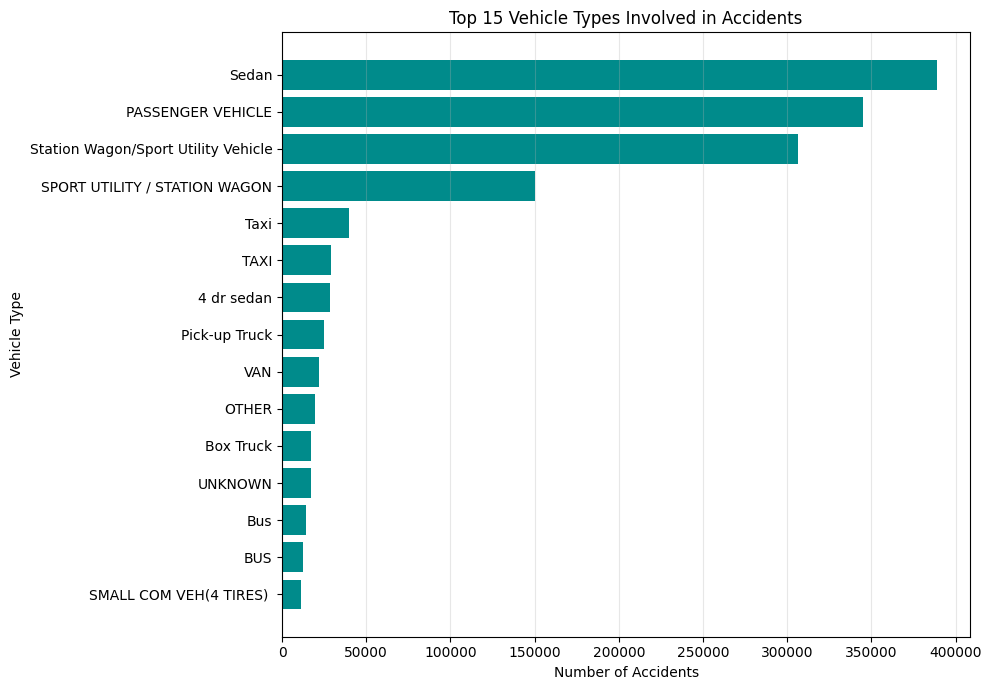

In [64]:
# ============================================
# STEP 58 — TOP VEHICLE TYPES
# ============================================

print("========== TOP VEHICLE TYPES ==========")

vehicle_counts = (
    eda_df["VEHICLE TYPE CODE 1"]
    .dropna()
    .value_counts()
)

print("Top 15 vehicle types:")

display(
    vehicle_counts
    .head(15)
    .to_frame("Accident Count")
)

top_vehicles = (
    vehicle_counts
    .head(15)
    .sort_values()
)

# Graph
plt.figure(figsize=(10, 7))

plt.barh(
    top_vehicles.index,
    top_vehicles.values,
    color="darkcyan"
)

plt.xlabel("Number of Accidents")
plt.ylabel("Vehicle Type")
plt.title(
    "Top 15 Vehicle Types Involved in Accidents"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

========== HOURLY TRAFFIC VS ACCIDENT PATTERN ==========


,ACCIDENT_HOUR,Accident_Count,Average_Traffic
0,0,45987,564.429448
1,1,24443,396.901639
2,2,18593,360.233766
3,3,16049,257.381579
4,4,18330,302.207317
5,5,20212,360.712644
6,6,32232,649.224806
7,7,44677,904.298507
8,8,84929,797.788660
9,9,83035,763.303763


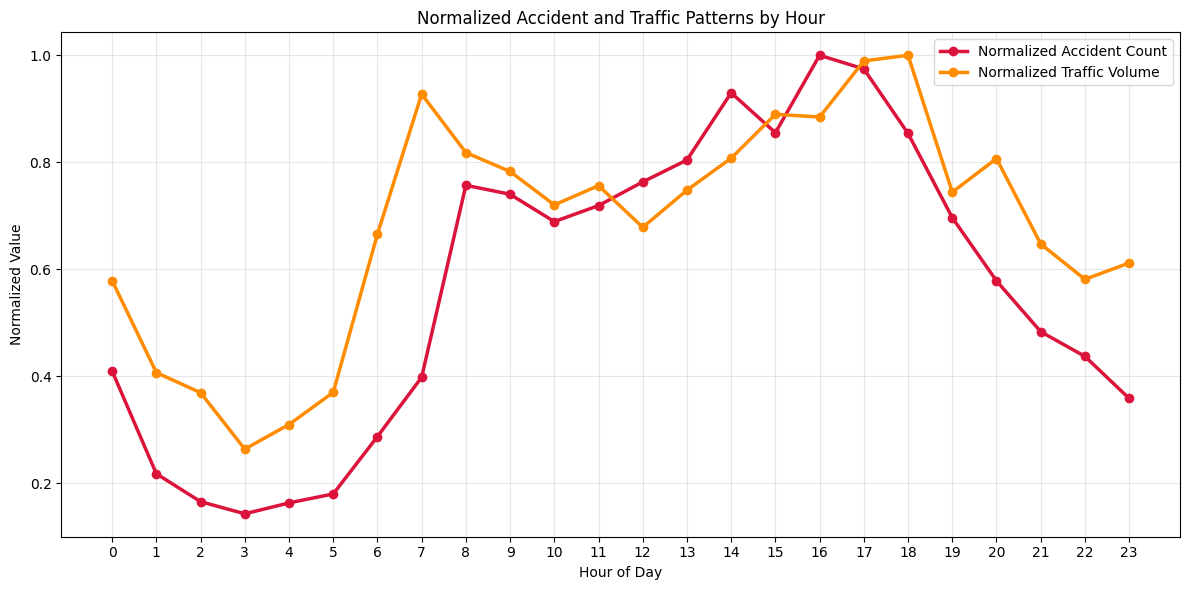

In [65]:
# ============================================
# STEP 59 — HOURLY TRAFFIC VS ACCIDENT PATTERN
# ============================================

print("========== HOURLY TRAFFIC VS ACCIDENT PATTERN ==========")

hourly_pattern = (
    eda_df
    .groupby("ACCIDENT_HOUR")
    .agg(
        Accident_Count=("COLLISION_ID", "count"),
        Average_Traffic=("Traffic_Volume", "mean")
    )
    .reset_index()
)

display(hourly_pattern)

# Normalize both variables for comparison
hourly_pattern["Accident_Normalized"] = (
    hourly_pattern["Accident_Count"]
    /
    hourly_pattern["Accident_Count"].max()
)

hourly_pattern["Traffic_Normalized"] = (
    hourly_pattern["Average_Traffic"]
    /
    hourly_pattern["Average_Traffic"].max()
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_pattern["ACCIDENT_HOUR"],
    hourly_pattern["Accident_Normalized"],
    marker="o",
    linewidth=2.5,
    color="crimson",
    label="Normalized Accident Count"
)

plt.plot(
    hourly_pattern["ACCIDENT_HOUR"],
    hourly_pattern["Traffic_Normalized"],
    marker="o",
    linewidth=2.5,
    color="darkorange",
    label="Normalized Traffic Volume"
)

plt.xlabel("Hour of Day")
plt.ylabel("Normalized Value")
plt.title(
    "Normalized Accident and Traffic Patterns by Hour"
)

plt.xticks(range(24))
plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# ============================================
# STEP 60 — FINAL EDA SUMMARY
# ============================================

print("========== FINAL EDA SUMMARY ==========")

print("\nDATASET")
print("--------------------------------")
print("Rows:", len(eda_df))
print("Columns:", len(eda_df.columns))

print("\nTEMPORAL")
print("--------------------------------")
print(
    "Peak accident hour:",
    eda_df["ACCIDENT_HOUR"].mode()[0]
)

print(
    "Peak accident month:",
    eda_df["ACCIDENT_MONTH"].mode()[0]
)

print(
    "Peak accident day:",
    eda_df["ACCIDENT_DAY_OF_WEEK"].mode()[0]
)

print("\nTRAFFIC")
print("--------------------------------")
print(
    "Mean traffic volume:",
    round(
        eda_df["Traffic_Volume"].mean(),
        2
    )
)

print(
    "Median traffic volume:",
    round(
        eda_df["Traffic_Volume"].median(),
        2
    )
)

print("\nSPATIAL MATCHING")
print("--------------------------------")
print(
    "Median accident-to-segment distance:",
    round(
        eda_df["DISTANCE_METERS"].median(),
        2
    ),
    "meters"
)

print(
    "Mean accident-to-segment distance:",
    round(
        eda_df["DISTANCE_METERS"].mean(),
        2
    ),
    "meters"
)

print("\nSEVERITY")
print("--------------------------------")

severity_summary = (
    eda_df["ACCIDENT_SEVERITY"]
    .value_counts()
)

display(
    severity_summary.to_frame(
        "Accident Count"
    )
)

print("\nBOROUGH")
print("--------------------------------")

top_borough = (
    eda_df["BOROUGH"]
    .dropna()
    .value_counts()
    .head(5)
)

display(
    top_borough.to_frame(
        "Accident Count"
    )
)

print("\nTOP CONTRIBUTING FACTORS")
print("--------------------------------")

display(
    eda_df[
        "CONTRIBUTING FACTOR VEHICLE 1"
    ]
    .dropna()
    .value_counts()
    .head(10)
    .to_frame("Accident Count")
)

print("\n========== EDA COMPLETE ==========")

========== FINAL EDA SUMMARY ==========

DATASET
--------------------------------
Rows: 1526397
Columns: 44

TEMPORAL
--------------------------------
Peak accident hour: 16
Peak accident month: 10
Peak accident day: Friday

TRAFFIC
--------------------------------
Mean traffic volume: 748.47
Median traffic volume: 542.0

SPATIAL MATCHING
--------------------------------
Median accident-to-segment distance: 243.29 meters
Mean accident-to-segment distance: 358.35 meters

SEVERITY
--------------------------------


,Accident Count
ACCIDENT_SEVERITY,
Property/No Reported Injury,1217742
Injury,306851
Fatal,1804



BOROUGH
--------------------------------


,Accident Count
BOROUGH,
BROOKLYN,369615
QUEENS,313010
MANHATTAN,273775
BRONX,167143
STATEN ISLAND,48614



TOP CONTRIBUTING FACTORS
--------------------------------


,Accident Count
CONTRIBUTING FACTOR VEHICLE 1,
Unspecified,545047
Driver Inattention/Distraction,297482
Failure to Yield Right-of-Way,90464
Following Too Closely,76392
Backing Unsafely,59956
Other Vehicular,48385
Passing or Lane Usage Improper,38556
Fatigued/Drowsy,37147
Turning Improperly,37145



========== EDA COMPLETE ==========


In [67]:
from google.colab import files

file_path = "/content/UrbanRisk_AI_Integrated_Dataset.csv"

files.download(file_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
# ============================================
# DOWNLOAD COMPLETE FINAL DATASET
# ALL 41 COLUMNS
# ============================================

print("Shape:", final_integrated_df.shape)
print("Number of columns:", len(final_integrated_df.columns))

print("\nAll columns:")
print(final_integrated_df.columns.tolist())

# Save complete CSV
output_path = "/content/UrbanRisk_AI_Integrated_Dataset_FULL.csv"

final_integrated_df.to_csv(
    output_path,
    index=False
)

print("\nCSV saved successfully!")
print("Rows:", len(final_integrated_df))
print("Columns:", len(final_integrated_df.columns))
print("File:", output_path)

Shape: (1526397, 41)
Number of columns: 41

All columns:
['COLLISION_ID', 'CRASH DATE', 'CRASH TIME', 'CRASH_DATE_DT', 'ACCIDENT_YEAR', 'ACCIDENT_MONTH', 'ACCIDENT_DAY_OF_WEEK', 'ACCIDENT_HOUR', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER_OF_PERSONS_INJURED', 'NUMBER_OF_PERSONS_KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5', 'SegmentID', 'DISTANCE_METERS', 'ACCIDENT_DATE_KEY', 'TRAFFIC_DATE', 'TRAFFIC_HOUR', 'Traffic_Volume', 'Traffic_Observations']

CSV saved successfully!
Rows: 1526397
Col

# PHASE 6 — MACHINE LEARNING IMPLEMENTATION

This phase applies:
1. Polynomial Regression for accident-count prediction
2. Logistic Regression for accident-severity classification
3. Performance evaluation and interpretation

In [70]:
# ============================================
# STEP 61 — POLYNOMIAL REGRESSION
# ============================================

print("========== POLYNOMIAL REGRESSION ==========")

# Import required libraries
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------
# STEP 1 — PREPARE HOURLY DATA
# --------------------------------------------

regression_df = hourly_analysis[
    [
        "ACCIDENT_HOUR",
        "Accident_Count"
    ]
].copy()

print("Regression dataset:")

display(regression_df)

# --------------------------------------------
# STEP 2 — DEFINE INPUT AND TARGET
# --------------------------------------------

X = regression_df[
    ["ACCIDENT_HOUR"]
]

y = regression_df[
    "Accident_Count"
]

print("\nInput feature:")
print("ACCIDENT_HOUR")

print("\nTarget:")
print("Accident_Count")


========== POLYNOMIAL REGRESSION ==========
Regression dataset:


,ACCIDENT_HOUR,Accident_Count
0,0,45987
1,1,24443
2,2,18593
3,3,16049
4,4,18330
5,5,20212
6,6,32232
7,7,44677
8,8,84929
9,9,83035



Input feature:
ACCIDENT_HOUR

Target:
Accident_Count


In [71]:
# --------------------------------------------
# STEP 3 — CREATE POLYNOMIAL FEATURES
# --------------------------------------------

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X)

# --------------------------------------------
# STEP 4 — TRAIN POLYNOMIAL REGRESSION MODEL
# --------------------------------------------

model = LinearRegression()

model.fit(
    X_poly,
    y
)

# --------------------------------------------
# STEP 5 — MAKE PREDICTIONS
# --------------------------------------------

y_pred = model.predict(
    X_poly
)

# --------------------------------------------
# STEP 6 — EVALUATE MODEL
# --------------------------------------------

mae = mean_absolute_error(
    y,
    y_pred
)

mse = mean_squared_error(
    y,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y,
    y_pred
)

print("\n========== MODEL PERFORMANCE ==========")

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))



========== MODEL PERFORMANCE ==========
MAE : 14441.16
MSE : 329598213.84
RMSE: 18154.84
R²  : 0.6584



Actual vs Predicted Accident Count:


,ACCIDENT_HOUR,Accident_Count,Predicted_Accident_Count
0,0,45987,-1408.519615
1,1,24443,10807.498980
2,2,18593,22128.547387
3,3,16049,32554.625605
4,4,18330,42085.733635
5,5,20212,50721.871476
6,6,32232,58463.039129
7,7,44677,65309.236593
8,8,84929,71260.463869
9,9,83035,76316.720956


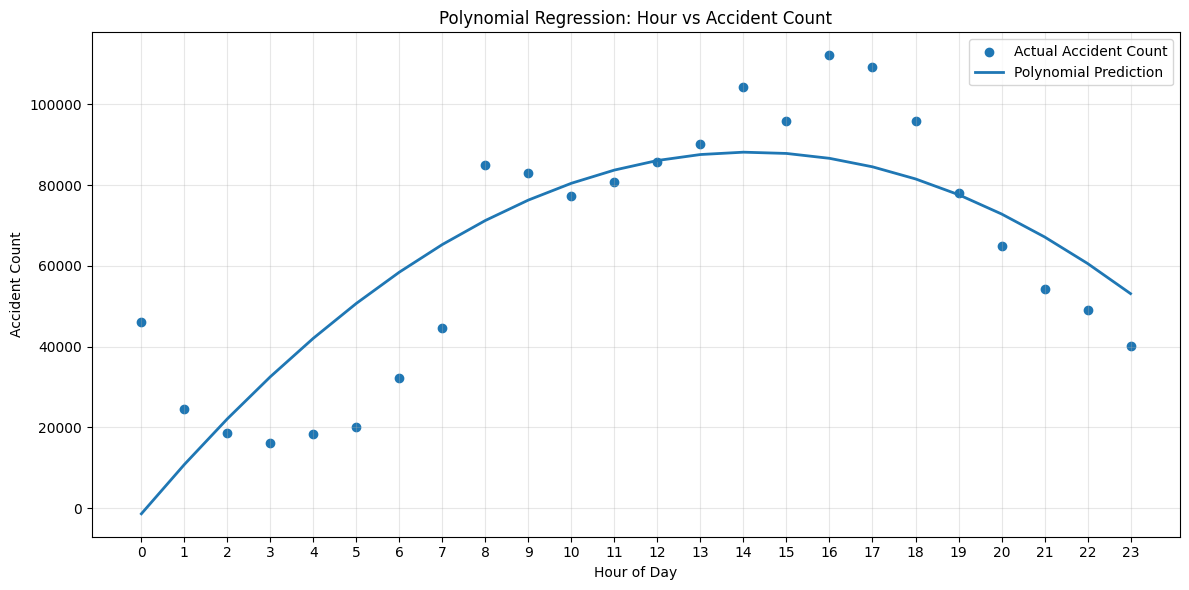

In [72]:

# --------------------------------------------
# STEP 7 — CREATE RESULT TABLE
# --------------------------------------------

regression_results = regression_df.copy()

regression_results[
    "Predicted_Accident_Count"
] = y_pred

print("\nActual vs Predicted Accident Count:")

display(
    regression_results
)

# --------------------------------------------
# STEP 8 — VISUALIZE RESULTS
# --------------------------------------------

plt.figure(figsize=(12, 6))

plt.scatter(
    regression_df["ACCIDENT_HOUR"],
    y,
    label="Actual Accident Count"
)

plt.plot(
    regression_df["ACCIDENT_HOUR"],
    y_pred,
    linewidth=2,
    label="Polynomial Prediction"
)

plt.xlabel("Hour of Day")
plt.ylabel("Accident Count")

plt.title(
    "Polynomial Regression: Hour vs Accident Count"
)

plt.xticks(range(24))

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [73]:
# ============================================
# STEP 62 — LOGISTIC REGRESSION CLASSIFICATION
# ============================================

print("========== LOGISTIC REGRESSION CLASSIFICATION ==========")

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------
# 1. CREATE BINARY CLASSIFICATION TARGET
# ------------------------------------------------

classification_df = eda_df.copy()

classification_df["SEVERITY_CLASS"] = np.where(
    classification_df["ACCIDENT_SEVERITY"].isin(
        ["Fatal", "Injury"]
    ),
    "Serious",
    "Non-Serious"
)

print("\n========== CLASS DISTRIBUTION ==========")

print(
    classification_df["SEVERITY_CLASS"]
    .value_counts()
)


========== LOGISTIC REGRESSION CLASSIFICATION ==========

========== CLASS DISTRIBUTION ==========
SEVERITY_CLASS
Non-Serious    1217742
Serious         308655
Name: count, dtype: int64


In [74]:

# ------------------------------------------------
# 2. SELECT FEATURES
# ------------------------------------------------

features = [
    "ACCIDENT_HOUR",
    "ACCIDENT_MONTH",
    "LATITUDE",
    "LONGITUDE",
    "DISTANCE_METERS",
    "Traffic_Volume"
]

classification_data = classification_df[
    features + ["SEVERITY_CLASS"]
].copy()

classification_data = classification_data.dropna(
    subset=["SEVERITY_CLASS"]
)

X = classification_data[features]

y = classification_data["SEVERITY_CLASS"]

print("\n========== FEATURES ==========")

print(features)

print("\nTarget:")
print("SEVERITY_CLASS")

print("\nDataset shape:")
print(classification_data.shape)




========== FEATURES ==========
['ACCIDENT_HOUR', 'ACCIDENT_MONTH', 'LATITUDE', 'LONGITUDE', 'DISTANCE_METERS', 'Traffic_Volume']

Target:
SEVERITY_CLASS

Dataset shape:
(1526397, 7)


In [79]:
# ------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n========== TRAIN-TEST SPLIT ==========")

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# ------------------------------------------------
# 4. BUILD LOGISTIC REGRESSION PIPELINE
# ------------------------------------------------

logistic_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)
        )
    ]
)



========== TRAIN-TEST SPLIT ==========
Training samples: 1221117
Testing samples : 305280


In [80]:

# ------------------------------------------------
# 5. TRAIN MODEL
# ------------------------------------------------

logistic_model.fit(
    X_train,
    y_train
)

print("\nLogistic Regression model trained successfully.")

# ------------------------------------------------
# 6. PREDICTION
# ------------------------------------------------

y_pred = logistic_model.predict(
    X_test
)

# ------------------------------------------------
# 7. PERFORMANCE METRICS
# ------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

print("\n========== CLASSIFICATION PERFORMANCE ==========")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))



Logistic Regression model trained successfully.

========== CLASSIFICATION PERFORMANCE ==========
Accuracy : 0.5431
Precision: 0.2226
Recall   : 0.5053
F1 Score : 0.3091


In [81]:

# ------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred
    )
)



========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Non-Serious       0.82      0.55      0.66    243549
     Serious       0.22      0.51      0.31     61731

    accuracy                           0.54    305280
   macro avg       0.52      0.53      0.48    305280
weighted avg       0.70      0.54      0.59    305280




========== CONFUSION MATRIX ==========
[[134618 108931]
 [ 30539  31192]]


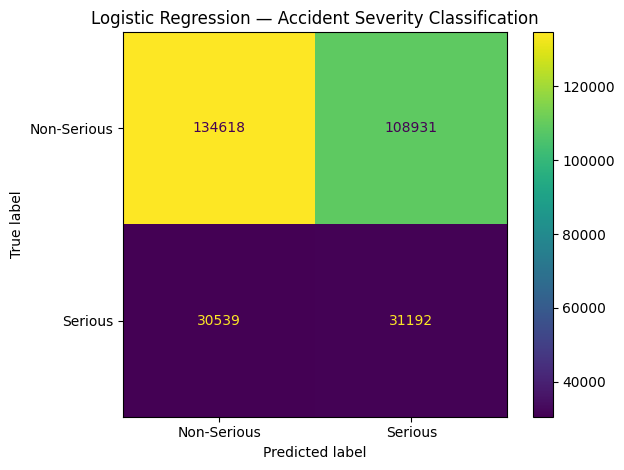

In [109]:

# ------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Non-Serious", "Serious"]
)

print("\n========== CONFUSION MATRIX ==========")

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Serious", "Serious"]
)

disp.plot()

plt.title(
    "Logistic Regression — Accident Severity Classification"
)

plt.tight_layout()

plt.show()

In [110]:
print(cm)

[[134618 108931]
 [ 30539  31192]]


In [111]:
# ============================================
# STEP 62 — PREPARE DATA FOR LINEAR SVM
# ============================================

print("========== LINEAR SVM PREPARATION ==========")

# Use the same preprocessed data and train-test split
# used for Logistic Regression

X_train_svm = preprocessor.fit_transform(X_train)
X_test_svm = preprocessor.transform(X_test)

print("Training data shape :", X_train_svm.shape)
print("Testing data shape  :", X_test_svm.shape)

print("\nTarget distribution in training data:")
print(y_train.value_counts())

print("\nTarget distribution in testing data:")
print(y_test.value_counts())

========== LINEAR SVM PREPARATION ==========
Training data shape : (1221117, 15)
Testing data shape  : (305280, 15)

Target distribution in training data:
Severity_Class
Non-Serious    974193
Serious        246924
Name: count, dtype: int64

Target distribution in testing data:
Severity_Class
Non-Serious    243549
Serious         61731
Name: count, dtype: int64


In [112]:
# ============================================
# STEP 63 — LINEAR SVM TRAINING
# ============================================

print("========== LINEAR SVM TRAINING ==========")

from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=2000
)

svm_model.fit(
    X_train_svm,
    y_train
)

print("Linear SVM training completed successfully.")

========== LINEAR SVM TRAINING ==========
Linear SVM training completed successfully.


In [113]:
# ============================================
# STEP 64 — LINEAR SVM EVALUATION
# ============================================

print("========== LINEAR SVM EVALUATION ==========")

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make predictions on test data
y_pred_svm = svm_model.predict(X_test_svm)

# Accuracy
svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

print("SVM Accuracy:", round(svm_accuracy, 4))

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

print("\n========== CONFUSION MATRIX ==========")

svm_cm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["Non-Serious", "Serious"]
)

print(svm_cm)

========== LINEAR SVM EVALUATION ==========
SVM Accuracy: 0.5393

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Non-Serious       0.82      0.54      0.65    243549
     Serious       0.22      0.52      0.31     61731

    accuracy                           0.54    305280
   macro avg       0.52      0.53      0.48    305280
weighted avg       0.70      0.54      0.58    305280


========== CONFUSION MATRIX ==========
[[132528 111021]
 [ 29621  32110]]


In [114]:
# ============================================
# STEP 65 — MODEL COMPARISON
# ============================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression predictions
# y_pred should already exist from the Logistic Regression evaluation

logistic_accuracy = accuracy_score(
    y_test,
    y_pred
)

logistic_precision = precision_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

logistic_recall = recall_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

logistic_f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Serious"
)

# Linear SVM metrics
svm_precision = precision_score(
    y_test,
    y_pred_svm,
    pos_label="Serious"
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    pos_label="Serious"
)

svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    pos_label="Serious"
)

# Comparison table
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        logistic_accuracy,
        svm_accuracy
    ],
    "Serious Precision": [
        logistic_precision,
        svm_precision
    ],
    "Serious Recall": [
        logistic_recall,
        svm_recall
    ],
    "Serious F1": [
        logistic_f1,
        svm_f1
    ]
})

# Display percentages
comparison_display = comparison_df.copy()

for column in [
    "Accuracy",
    "Serious Precision",
    "Serious Recall",
    "Serious F1"
]:
    comparison_display[column] = (
        comparison_display[column] * 100
    ).round(2)

display(comparison_display)

,Model,Accuracy,Serious Precision,Serious Recall,Serious F1
0,Logistic Regression,54.31,22.26,50.53,30.91
1,Linear SVM,53.93,22.43,52.02,31.35


# ML RESULTS AND INTERPRETATION

## 1. Polynomial Regression

Polynomial Regression was used to model the relationship between accident hour and hourly accident count.

The model achieved an R² score of 0.6584, indicating that approximately 65.84% of the variation in hourly accident counts is explained by the fitted polynomial relationship.

The MAE was 14,441.16 and the RMSE was 18,154.84.

The model captures the overall variation in accident counts across different hours, but it should be interpreted as a curve-fitting analysis rather than a production forecasting model because only 24 hourly observations were used.

---

## 2. Classification

Accident severity was converted into two classes:

- Serious: Fatal or Injury
- Non-Serious: Property/No Reported Injury

The dataset was imbalanced, with Non-Serious accidents forming the majority class.

Therefore, balanced class weights were used in both Logistic Regression and Linear SVM to give greater importance to the minority Serious class.

---

## 3. Logistic Regression

Logistic Regression achieved an overall accuracy of 54.31%.

For the Serious class:

- Precision = 22.26%
- Recall = 50.53%
- F1-score = 30.91%

The model was able to identify approximately half of the actual Serious accidents.

Accuracy alone is not sufficient for evaluating this problem because of the class imbalance.

---

## 4. Linear SVM

Linear SVM achieved an overall accuracy of 53.93%.

For the Serious class:

- Precision = 22.43%
- Recall = 52.02%
- F1-score = 31.35%

Compared with Logistic Regression, Linear SVM achieved slightly higher recall and F1-score for the Serious class.

---

## 5. Comparative Performance Analysis

Both classification models produced similar results.

Logistic Regression achieved slightly higher overall accuracy:

54.31% vs 53.93%.

Linear SVM achieved slightly better Serious-class detection:

- Recall: 52.02% vs 50.53%
- F1-score: 31.35% vs 30.91%

Therefore, Linear SVM provides a slight advantage when the priority is identifying Serious accidents, while Logistic Regression provides slightly higher overall accuracy.

The similar performance of both models suggests that the current features have limited predictive power for accident severity.

---

## 6. Overall Finding

The analysis shows that accident occurrence varies considerably by hour, and Polynomial Regression captures part of this hourly pattern.

For severity classification, both Logistic Regression and Linear SVM can identify Serious accidents to some extent, but their performance remains moderate.

Therefore, the results should be interpreted as an analysis of patterns and baseline predictive performance rather than as a production-ready accident prediction system.